# Fase exploratoria de Machine Learning — Telemetría

Este cuaderno desarrolla la **primera fase de un algoritmo de Machine Learning no supervisado** sobre el dataset
`BUS7838_20260103_20260331.csv`.

El objetivo es conocer la estructura y calidad de los datos, preparar las variables, crear indicadores de rendimiento
energético, estudiar correlaciones y reducción de dimensionalidad, y realizar una primera exploración de patrones
mediante **K-Means, DBSCAN y clustering aglomerativo**.

> **Criterio metodológico:** no todos los pasos propuestos se aplican de forma automática. El cuaderno incluye
validaciones para evitar transformar datos sin justificación y deja las etapas experimentales o de mayor consumo
computacional separadas y comentadas.

## Estructura
1. Conexión con Drive y carga del CSV.
2. Inicialización e importación de librerías.
3. Exploración y tratamiento de datos.
4. Normalización, varianza y PCA.
5. Creación de nuevas variables de rendimiento.
6. Exploración de clusters.
7. Análisis experimental de matriz transpuesta.
8. Conclusiones de la fase exploratoria.

## 1. Conectar Google Drive y localizar el archivo

Se utiliza la misma estructura de carpetas empleada en los algoritmos anteriores. El archivo se busca inicialmente en
`/content/drive/MyDrive/MANTENIMIENTOESA/datasets_filtrados/`.

El bloque valida que el archivo exista antes de continuar. Si en Drive se mueve a otra carpeta, solo se debe modificar
`CARPETA_DATOS`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

CARPETA_DATOS = Path('/content/drive/MyDrive/MANTENIMIENTOESA/datasets_filtrados/')
NOMBRE_ARCHIVO = 'BUS7806_Exploracion.csv'
RUTA_ARCHIVO = CARPETA_DATOS / NOMBRE_ARCHIVO

print('Ruta esperada:', RUTA_ARCHIVO)
print('¿Existe el archivo?:', RUTA_ARCHIVO.exists())

if not RUTA_ARCHIVO.exists():
    # Búsqueda alternativa dentro de MANTENIMIENTOESA.
    coincidencias = list(Path('/content/drive/MyDrive/MANTENIMIENTOESA').rglob(NOMBRE_ARCHIVO))
    if coincidencias:
        RUTA_ARCHIVO = coincidencias[0]
        print('Archivo encontrado en:', RUTA_ARCHIVO)
    else:
        raise FileNotFoundError(
            f'No se encontró {NOMBRE_ARCHIVO}. '
            'Revisa que el archivo esté guardado en Drive.'
        )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ruta esperada: /content/drive/MyDrive/MANTENIMIENTOESA/datasets_filtrados/BUS7806_Exploracion.csv
¿Existe el archivo?: True


## 2. Inicialización e importación de librerías

Se cargan las librerías necesarias para manipulación de datos, visualización y aprendizaje no supervisado.

Se fija una semilla para que los resultados de K-Means y los muestreos sean reproducibles. También se definen límites
para las gráficas y algunos algoritmos, evitando sobrecargar la RAM de Colab si el CSV contiene muchos registros.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_selection import VarianceThreshold

SEMILLA = 42

# Límites de seguridad para no saturar la RAM en gráficos/clustering.
MAX_FILAS_GRAFICOS = 50_000
MAX_FILAS_CLUSTER = 30_000
MAX_FILAS_DBSCAN = 15_000
MAX_FILAS_AGLOMERATIVO = 8_000

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## 3. Carga eficiente y exploración del dataset

Primero se detecta el separador del CSV y se carga el archivo. Como el dataset corresponde a un solo vehículo y un
periodo ya filtrado, puede trabajarse directamente con él; aun así, el bloque conserva opciones de ahorro de memoria.

La fecha se convierte a tipo `datetime`, porque el orden temporal es indispensable para imputar valores anteriores y
calcular diferencias de odómetro y consumo.

In [3]:
import csv

def detectar_separador(ruta, encoding='utf-8-sig'):
    with open(ruta, 'r', encoding=encoding, errors='replace') as f:
        muestra = f.read(50_000)
    try:
        return csv.Sniffer().sniff(muestra, delimiters=',;\t|').delimiter
    except csv.Error:
        return ','

SEPARADOR = detectar_separador(RUTA_ARCHIVO)
print('Separador detectado:', repr(SEPARADOR))

df = pd.read_csv(
    RUTA_ARCHIVO,
    sep=SEPARADOR,
    encoding='utf-8-sig',
    low_memory=False
)

# Conversión temporal si la variable está disponible.
if 'fechaHoraLecturaDato' in df.columns:
    df['fechaHoraLecturaDato'] = pd.to_datetime(
        df['fechaHoraLecturaDato'],
        errors='coerce',
        dayfirst=True
    )

# Conversión explícita de variables conocidas de telemetría.
columnas_numericas_esperadas = [
    'kilometrosOdometro',
    'consumoEnergia',
    'regeneracionEnergia',
    'nivelRestanteEnergia'
]

for col in columnas_numericas_esperadas:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Orden cronológico.
columnas_orden = [c for c in ['idVehiculo', 'fechaHoraLecturaDato'] if c in df.columns]
if columnas_orden:
    df = df.sort_values(columnas_orden).reset_index(drop=True)

print(f'Filas: {len(df):,}')
print(f'Columnas: {df.shape[1]}')
display(df.head())

Separador detectado: ','
Filas: 377
Columnas: 35


,sentidoMarcha,memRamSts,usoCpuSts,temperaturaSts,regeneracionEnergia,idRuta,consumoCombustible,nivelRestanteEnergia,estadoDesgasteFrenos,porcentajeEnergiaGenerada,tramaRetransmitida,kilometrosOdometro,revolucionesMotor,temperaturaBaterias,codigoPeriodica,tipoFreno,idConductor,tecnologiaMotor,fechaHoraLecturaDato,presionAceiteMotor,fechaHoraEnvioDato,consumoEnergia,nivelTanqueCombustible,tipoTrama,aceleracionVehiculo,velocidadVehiculo,idVehiculo,temperaturaMotor,localizacionVehiculo.longitud,localizacionVehiculo.latitud,tipoBus,idOperador,memDiscoSts,idRegistro,versionTrama
0,0,35,5,22,239534,No Disponible,NaN,100,41,71.3900,False,"308,428.9750",0.0000,31,P60,2,No Disponible,3,2026-05-01 02:20:00,NaN,2026-05-01 02:20:01.518000,335529,NaN,1,0.0000,0.0000,BUS7806,35,-74.1281,4.4674,P,UA,97,283411,E.1.0.0
1,0,35,0,23,239534,No Disponible,NaN,100,40,71.3900,False,"308,428.9750",0.0000,31,P60,2,No Disponible,3,2026-05-01 02:24:00,NaN,2026-05-01 02:24:01.257000,335529,NaN,1,0.0000,0.0000,BUS7806,35,-74.1281,4.4674,P,UA,97,283427,E.1.0.0
2,0,34,0,25,239534,No Disponible,NaN,100,40,71.3900,False,"308,428.9750",0.0000,31,P60,2,No Disponible,3,2026-05-01 02:41:00,NaN,2026-05-01 02:41:01.767000,335529,NaN,1,0.0000,0.0000,BUS7806,35,-74.1282,4.4674,P,UA,97,283495,E.1.0.0
3,0,34,3,25,239534,No Disponible,NaN,100,40,71.3900,False,"308,428.9750",0.0000,31,P60,2,No Disponible,3,2026-05-01 02:44:00,NaN,2026-05-01 02:44:01.022000,335529,NaN,1,0.0000,0.0000,BUS7806,35,-74.1282,4.4674,P,UA,97,283507,E.1.0.0
4,0,34,0,25,239534,No Disponible,NaN,100,40,71.3900,False,"308,428.9750",0.0000,31,P60,2,No Disponible,3,2026-05-01 02:45:00,NaN,2026-05-01 02:45:01.032000,335529,NaN,1,0.0000,0.0000,BUS7806,35,-74.1282,4.4674,P,UA,97,283511,E.1.0.0


### 3.1 Información general del dataset

Este diagnóstico muestra el tipo de cada variable, cantidad y porcentaje de nulos, valores únicos y un ejemplo.
Permite diferenciar identificadores, variables categóricas, variables numéricas y campos que podrían no aportar
variabilidad al modelo.

In [4]:
resumen_estructura = pd.DataFrame({
    'Variable': df.columns,
    'Tipo': df.dtypes.astype(str).values,
    'No_nulos': df.notna().sum().values,
    'Nulos': df.isna().sum().values,
    'Porcentaje_nulos': (df.isna().mean() * 100).round(2).values,
    'Valores_unicos': [df[c].nunique(dropna=True) for c in df.columns],
    'Ejemplo': [
        df[c].dropna().iloc[0] if df[c].notna().any() else None
        for c in df.columns
    ]
})

display(resumen_estructura)

print('\nMemoria aproximada utilizada por el DataFrame:')
print(f"{df.memory_usage(deep=True).sum() / 1024**2:,.2f} MB")

if 'fechaHoraLecturaDato' in df.columns:
    print('\nPeriodo disponible:')
    print('Desde:', df['fechaHoraLecturaDato'].min())
    print('Hasta:', df['fechaHoraLecturaDato'].max())

,Variable,Tipo,No_nulos,Nulos,Porcentaje_nulos,Valores_unicos,Ejemplo
0,sentidoMarcha,int64,377,0,0.0000,2,0
1,memRamSts,int64,377,0,0.0000,14,35
2,usoCpuSts,int64,377,0,0.0000,19,5
3,temperaturaSts,int64,377,0,0.0000,25,22
4,regeneracionEnergia,int64,377,0,0.0000,126,239534
5,idRuta,object,377,0,0.0000,6,No Disponible
6,consumoCombustible,float64,0,377,100.0000,0,None
7,nivelRestanteEnergia,int64,377,0,0.0000,71,100
8,estadoDesgasteFrenos,int64,377,0,0.0000,5,41
9,porcentajeEnergiaGenerada,float64,377,0,0.0000,1,71.3900



Memoria aproximada utilizada por el DataFrame:
0.24 MB

Periodo disponible:
Desde: 2026-05-01 02:20:00
Hasta: 2026-05-03 21:29:00


### 3.2 Descripción estadística de los datos

Se presentan estadísticas descriptivas separando variables numéricas y categóricas. En las numéricas interesan
especialmente media, desviación estándar, percentiles, mínimo y máximo. En las categóricas se revisa la cantidad de
categorías y su frecuencia.

Este paso ayuda a identificar escalas muy diferentes, posibles valores extremos y variables prácticamente constantes.

In [5]:
columnas_numericas = df.select_dtypes(include='number').columns.tolist()
columnas_categoricas = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

print('Variables numéricas:', columnas_numericas)
print('Variables categóricas:', columnas_categoricas)

if columnas_numericas:
    print('\nDescripción numérica:')
    display(df[columnas_numericas].describe().T)

if columnas_categoricas:
    print('\nDescripción categórica:')
    display(df[columnas_categoricas].describe().T)

Variables numéricas: ['sentidoMarcha', 'memRamSts', 'usoCpuSts', 'temperaturaSts', 'regeneracionEnergia', 'consumoCombustible', 'nivelRestanteEnergia', 'estadoDesgasteFrenos', 'porcentajeEnergiaGenerada', 'kilometrosOdometro', 'revolucionesMotor', 'temperaturaBaterias', 'tipoFreno', 'tecnologiaMotor', 'presionAceiteMotor', 'consumoEnergia', 'nivelTanqueCombustible', 'tipoTrama', 'aceleracionVehiculo', 'velocidadVehiculo', 'temperaturaMotor', 'localizacionVehiculo.longitud', 'localizacionVehiculo.latitud', 'memDiscoSts', 'idRegistro']
Variables categóricas: ['idRuta', 'codigoPeriodica', 'idConductor', 'fechaHoraEnvioDato', 'idVehiculo', 'tipoBus', 'idOperador', 'versionTrama']

Descripción numérica:


,count,mean,std,min,25%,50%,75%,max
sentidoMarcha,377.0000,0.0027,0.0515,0.0000,0.0000,0.0000,0.0000,1.0000
memRamSts,377.0000,2.6711,5.6656,0.0000,1.0000,1.0000,2.0000,35.0000
usoCpuSts,377.0000,3.0928,7.5828,0.0000,0.0000,0.0000,3.0000,77.0000
temperaturaSts,377.0000,37.7321,5.5294,19.0000,35.0000,37.0000,43.0000,45.0000
regeneracionEnergia,377.0000,"239,657.4775",76.1372,"239,534.0000","239,587.0000","239,650.0000","239,733.0000","239,778.0000"
consumoCombustible,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivelRestanteEnergia,377.0000,64.1141,22.1709,18.0000,44.0000,64.0000,83.0000,100.0000
estadoDesgasteFrenos,377.0000,40.5968,2.7842,39.0000,40.0000,40.0000,40.0000,76.0000
porcentajeEnergiaGenerada,377.0000,71.3900,0.0000,71.3900,71.3900,71.3900,71.3900,71.3900
kilometrosOdometro,377.0000,"308,579.4153",86.6840,"308,428.9750","308,504.2550","308,578.3150","308,662.1750","308,713.3550"



Descripción categórica:


,count,unique,top,freq
idRuta,377,6,3-10,188
codigoPeriodica,377,1,P60,377
idConductor,377,1,No Disponible,377
fechaHoraEnvioDato,377,377,2026-05-03 21:29:01.067000,1
idVehiculo,377,1,BUS7806,377
tipoBus,377,1,P,377
idOperador,377,1,UA,377
versionTrama,377,1,E.1.0.0,377


### 3.3 Tratamiento de datos faltantes: ¿transformar o eliminar?

Para telemetría ordenada en el tiempo, **usar el dato anterior puede ser válido** cuando la ausencia es corta y la
variable cambia de forma gradual. Sin embargo, no es recomendable rellenar indiscriminadamente intervalos largos,
porque se fabricarían periodos artificialmente constantes.

Por ello se aplica `forward fill` (`ffill`) **dentro de cada vehículo y con un límite máximo de 5 registros
consecutivos**. Si las tramas son P60, esto equivale aproximadamente a cinco minutos. Los nulos que permanezcan se
conservarán en el dataset exploratorio y se eliminarán únicamente al construir matrices específicas para los modelos.

La fecha no se imputa. Tampoco se usa `backfill`, porque introduciría información futura en observaciones anteriores.

In [6]:
df_limpio = df.copy()

# Se excluyen identificadores y fecha del relleno.
columnas_no_imputar = [
    c for c in ['idVehiculo', 'fechaHoraLecturaDato']
    if c in df_limpio.columns
]

columnas_imputables = [
    c for c in df_limpio.columns
    if c not in columnas_no_imputar
]

nulos_antes = df_limpio[columnas_imputables].isna().sum()

if 'idVehiculo' in df_limpio.columns:
    df_limpio[columnas_imputables] = (
        df_limpio
        .groupby('idVehiculo', group_keys=False)[columnas_imputables]
        .ffill(limit=5)
    )
else:
    df_limpio[columnas_imputables] = df_limpio[columnas_imputables].ffill(limit=5)

nulos_despues = df_limpio[columnas_imputables].isna().sum()

comparacion_nulos = pd.DataFrame({
    'Nulos_antes': nulos_antes,
    'Nulos_despues_ffill': nulos_despues,
})
comparacion_nulos['Nulos_reemplazados'] = (
    comparacion_nulos['Nulos_antes'] - comparacion_nulos['Nulos_despues_ffill']
)

display(comparacion_nulos.sort_values('Nulos_antes', ascending=False))

,Nulos_antes,Nulos_despues_ffill,Nulos_reemplazados
consumoCombustible,377,377,0
nivelTanqueCombustible,377,377,0
presionAceiteMotor,377,377,0
sentidoMarcha,0,0,0
memRamSts,0,0,0
regeneracionEnergia,0,0,0
idRuta,0,0,0
temperaturaSts,0,0,0
usoCpuSts,0,0,0
porcentajeEnergiaGenerada,0,0,0


### 3.4 Conversión de `idRuta` mediante One-Hot Encoding

`idRuta` es una categoría nominal: el código de una ruta no significa que una ruta sea "mayor" o "menor" que otra.
Por esta razón se utiliza **One-Hot Encoding** y no codificación ordinal.

En esta fase se conserva además el campo original para interpretación. El one-hot se incorporará a la matriz del modelo
cuando existan al menos dos rutas distintas.

In [7]:
if 'idRuta' in df_limpio.columns:
    rutas = df_limpio['idRuta'].astype('string').fillna('SIN_RUTA')
    print('Número de rutas/categorías:', rutas.nunique())
    display(rutas.value_counts(dropna=False).rename('Registros').to_frame().head(30))

    try:
        encoder_ruta = OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False,
            dtype=np.float32
        )
    except TypeError:
        # Compatibilidad con versiones anteriores de scikit-learn.
        encoder_ruta = OneHotEncoder(
            handle_unknown='ignore',
            sparse=False,
            dtype=np.float32
        )

    ruta_ohe = encoder_ruta.fit_transform(rutas.to_frame())
    nombres_ruta = encoder_ruta.get_feature_names_out(['idRuta'])

    df_ruta_ohe = pd.DataFrame(
        ruta_ohe,
        columns=nombres_ruta,
        index=df_limpio.index
    )

    print('Variables One-Hot creadas:', len(nombres_ruta))
    display(df_ruta_ohe.head())
else:
    df_ruta_ohe = pd.DataFrame(index=df_limpio.index)
    print('No se encontró la variable idRuta.')

Número de rutas/categorías: 6


,Registros
idRuta,
3-10,188
3-4,79
TAP,32
DES,29
No Disponible,28
RET,21


Variables One-Hot creadas: 6


,idRuta_3-10,idRuta_3-4,idRuta_DES,idRuta_No Disponible,idRuta_RET,idRuta_TAP
0,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
1,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
2,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
3,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
4,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000


### 3.5 Matriz de correlación

La correlación se calcula únicamente entre variables numéricas. Se usa Pearson como primera aproximación lineal.

Una correlación alta no implica causalidad, pero ayuda a detectar variables redundantes. Si existen muchas variables,
se muestran las de mayor varianza para mantener una visualización legible.

,sentidoMarcha,memRamSts,usoCpuSts,temperaturaSts,regeneracionEnergia,nivelRestanteEnergia,estadoDesgasteFrenos,kilometrosOdometro,revolucionesMotor,temperaturaBaterias,consumoEnergia,aceleracionVehiculo,velocidadVehiculo,temperaturaMotor,localizacionVehiculo.longitud,localizacionVehiculo.latitud,memDiscoSts,idRegistro
sentidoMarcha,1.0000,-0.0150,-0.0210,0.0310,0.0190,0.0250,-0.0110,0.0210,-0.0360,0.0400,0.0220,0.0000,-0.0370,0.1030,-0.0730,-0.0740,-0.0150,0.0210
memRamSts,-0.0150,1.0000,0.0580,-0.5280,-0.3840,0.3480,0.0910,-0.4080,-0.1510,0.1660,-0.4000,0.0410,-0.1470,-0.1310,-0.3110,-0.2850,0.7550,-0.4170
usoCpuSts,-0.0210,0.0580,1.0000,-0.1390,-0.0470,0.1100,-0.0340,-0.0440,-0.0330,-0.0150,-0.0420,-0.0320,-0.0370,-0.0220,-0.0060,-0.0510,0.0550,-0.0400
temperaturaSts,0.0310,-0.5280,-0.1390,1.0000,0.7660,-0.5600,-0.2020,0.7620,-0.0250,0.5210,0.7560,0.0460,-0.0290,0.5020,0.0940,0.0340,-0.5130,0.7590
regeneracionEnergia,0.0190,-0.3840,-0.0470,0.7660,1.0000,-0.6520,-0.1360,0.9990,-0.0490,0.7790,0.9980,0.0370,-0.0550,0.4200,-0.1090,-0.0630,-0.4700,0.9970
nivelRestanteEnergia,0.0250,0.3480,0.1100,-0.5600,-0.6520,1.0000,0.1130,-0.6490,0.0200,-0.2520,-0.6590,-0.0190,0.0200,-0.1820,-0.2200,-0.1090,0.4620,-0.6370
estadoDesgasteFrenos,-0.0110,0.0910,-0.0340,-0.2020,-0.1360,0.1130,1.0000,-0.1390,-0.1090,-0.0760,-0.1390,0.0110,-0.1080,-0.0720,-0.2110,-0.2290,0.2080,-0.1400
kilometrosOdometro,0.0210,-0.4080,-0.0440,0.7620,0.9990,-0.6490,-0.1390,1.0000,-0.0400,0.7680,0.9990,0.0350,-0.0460,0.4100,-0.1020,-0.0650,-0.5010,0.9980
revolucionesMotor,-0.0360,-0.1510,-0.0330,-0.0250,-0.0490,0.0200,-0.1090,-0.0400,1.0000,-0.1160,-0.0420,0.0720,0.9980,0.0780,0.2640,0.1530,-0.1720,-0.0410
temperaturaBaterias,0.0400,0.1660,-0.0150,0.5210,0.7790,-0.2520,-0.0760,0.7680,-0.1160,1.0000,0.7680,0.0660,-0.1220,0.4320,-0.4070,-0.3550,-0.0140,0.7610


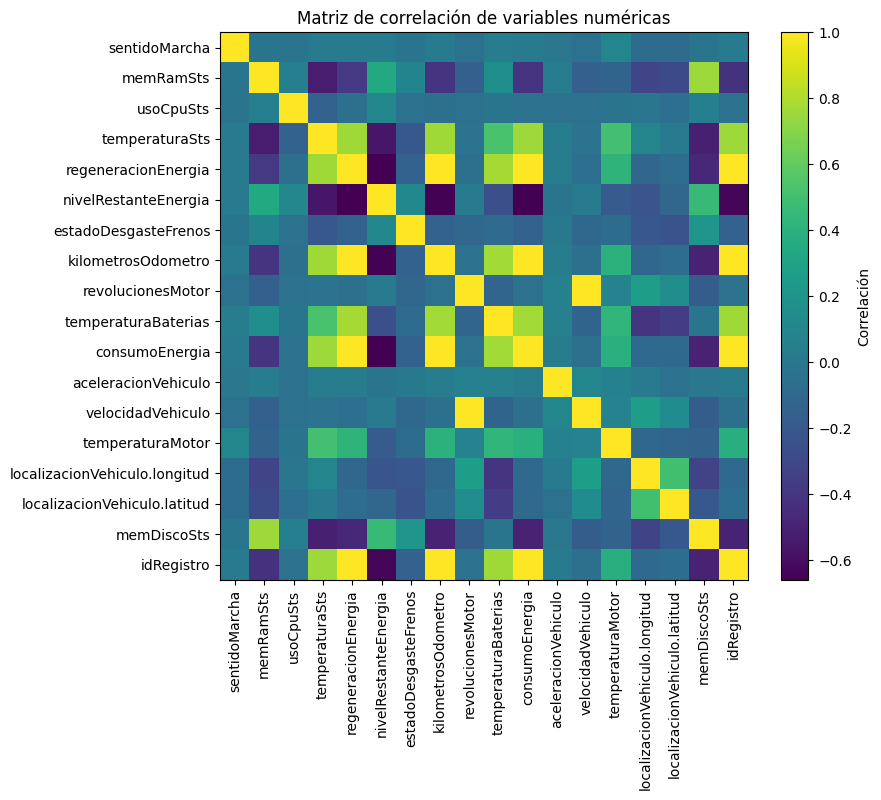

In [8]:
numericas_corr = df_limpio.select_dtypes(include='number').columns.tolist()

# Se eliminan variables numéricas constantes, porque su correlación no es informativa.
numericas_corr = [
    c for c in numericas_corr
    if df_limpio[c].nunique(dropna=True) > 1
]

if numericas_corr:
    if len(numericas_corr) > 25:
        varianzas_corr = df_limpio[numericas_corr].var(numeric_only=True).sort_values(ascending=False)
        columnas_corr_grafico = varianzas_corr.head(25).index.tolist()
        print('Se grafican las 25 variables numéricas con mayor varianza.')
    else:
        columnas_corr_grafico = numericas_corr

    matriz_corr = df_limpio[columnas_corr_grafico].corr()

    display(matriz_corr.round(3))

    fig, ax = plt.subplots(figsize=(max(8, len(columnas_corr_grafico)*0.5),
                                    max(6, len(columnas_corr_grafico)*0.45)))
    im = ax.imshow(matriz_corr, aspect='auto')
    ax.set_xticks(range(len(columnas_corr_grafico)))
    ax.set_yticks(range(len(columnas_corr_grafico)))
    ax.set_xticklabels(columnas_corr_grafico, rotation=90)
    ax.set_yticklabels(columnas_corr_grafico)
    fig.colorbar(im, ax=ax, label='Correlación')
    ax.set_title('Matriz de correlación de variables numéricas')
    plt.tight_layout()
    plt.show()
else:
    print('No hay suficientes variables numéricas variables para calcular correlación.')

### 3.6 Histogramas y boxplots

Los histogramas permiten observar la distribución, asimetrías y posibles concentraciones. Los boxplots facilitan la
detección visual de valores extremos.

Para no saturar Colab, si el dataset supera `MAX_FILAS_GRAFICOS` se toma una muestra reproducible únicamente para
graficar; los datos originales no se eliminan.

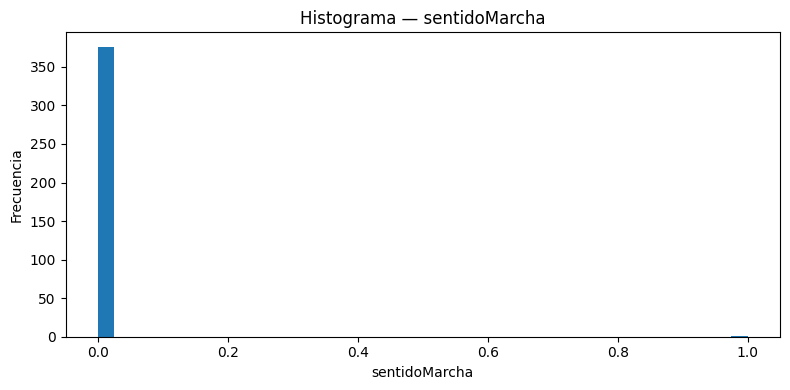

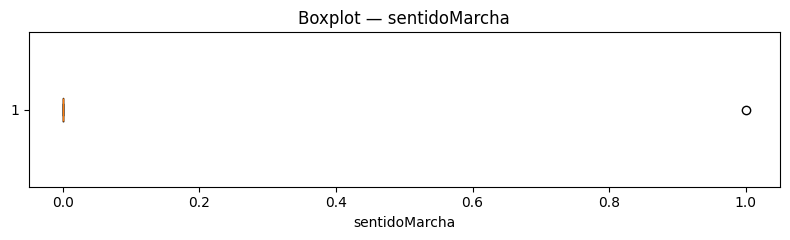

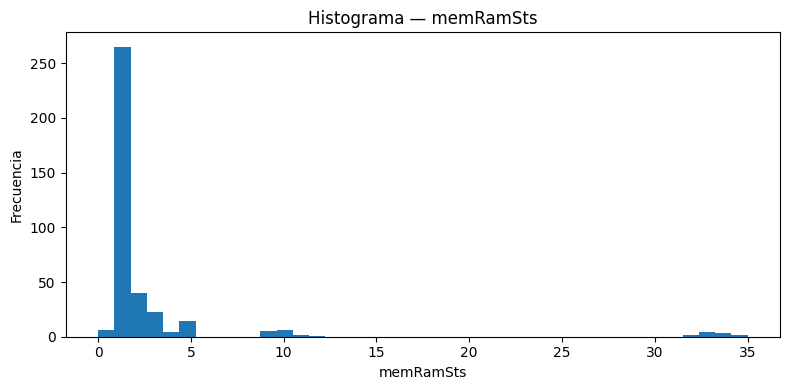

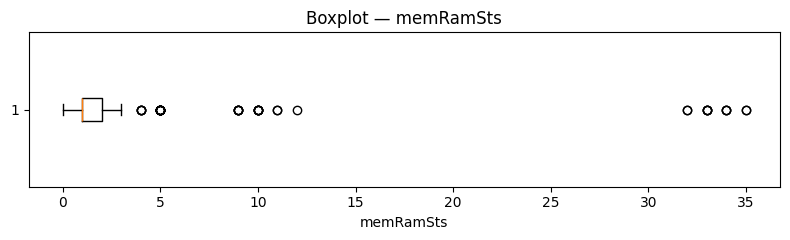

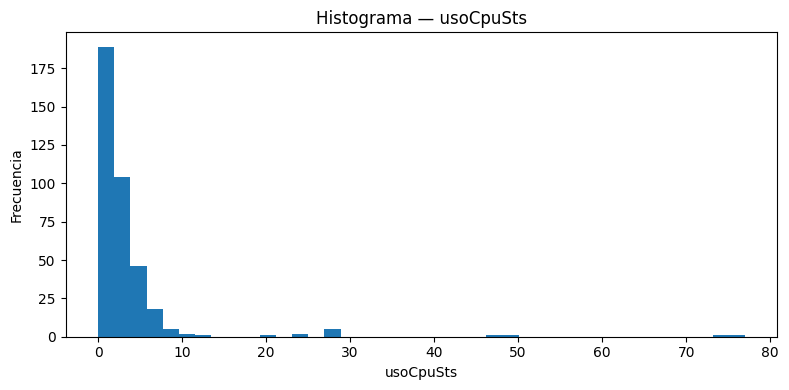

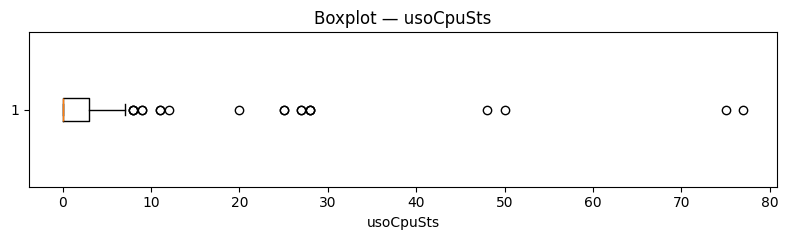

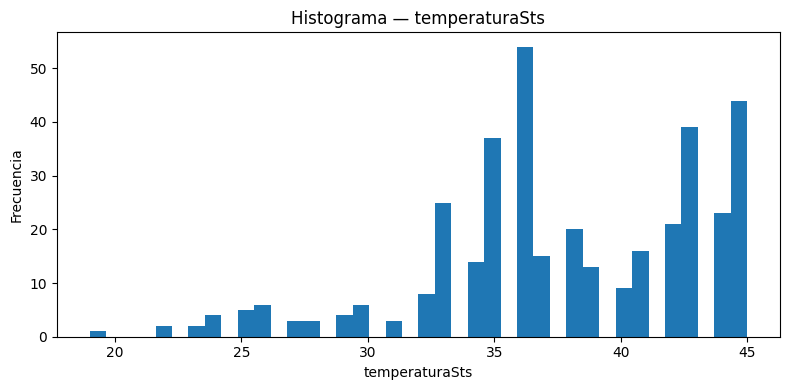

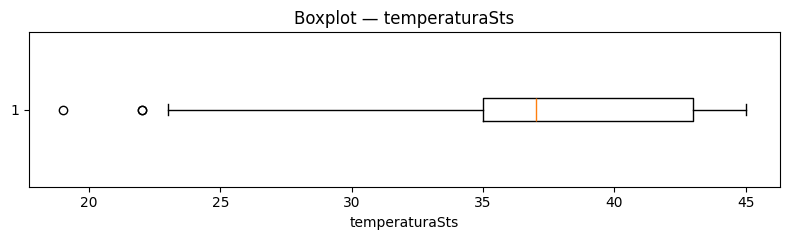

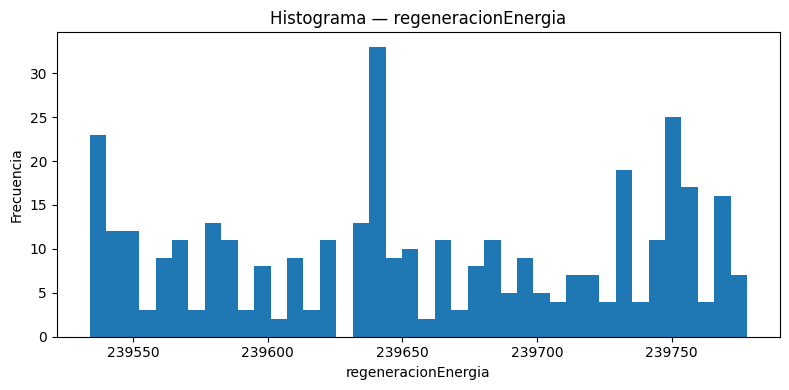

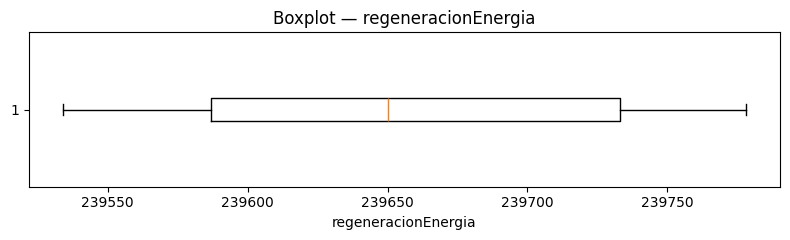

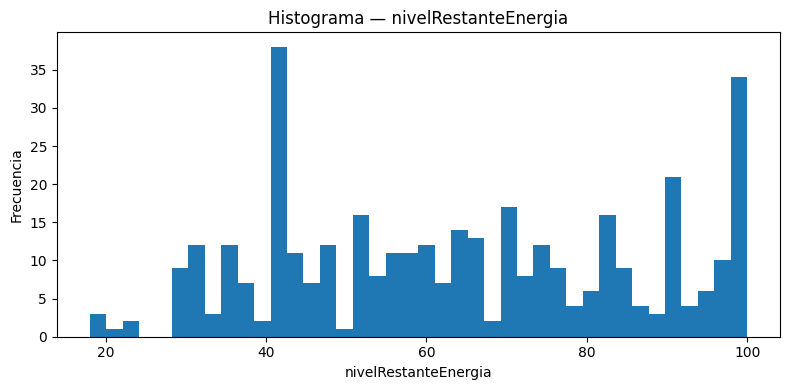

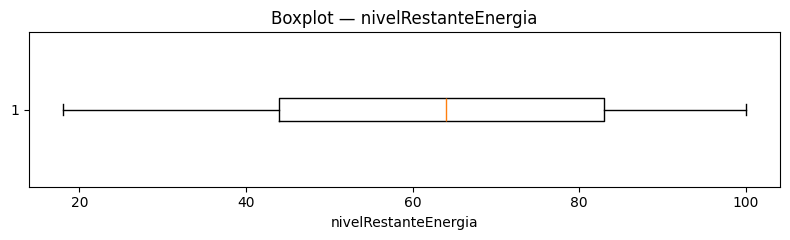

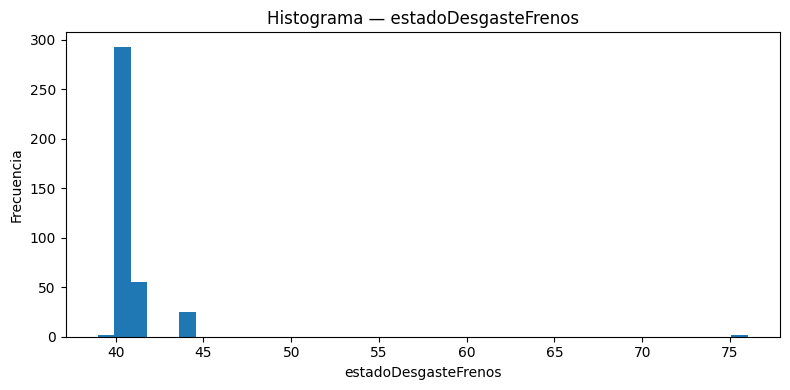

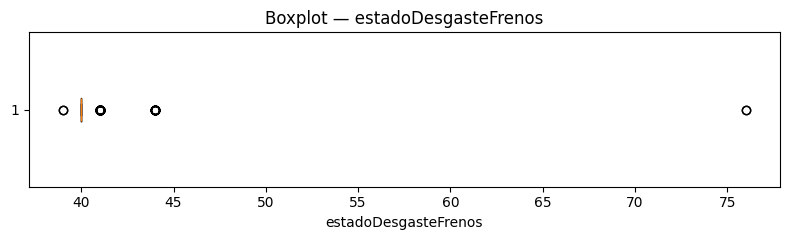

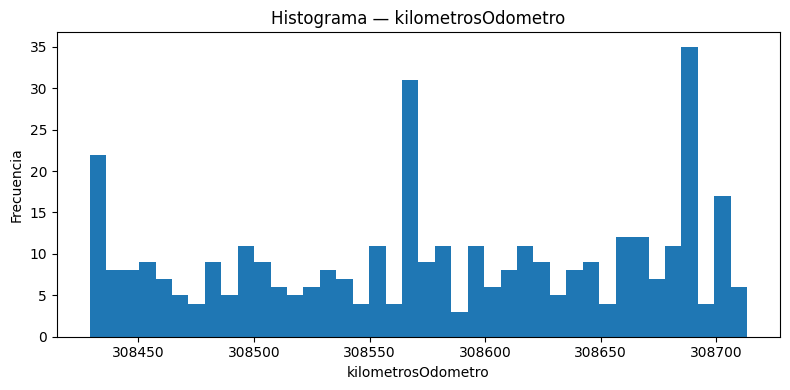

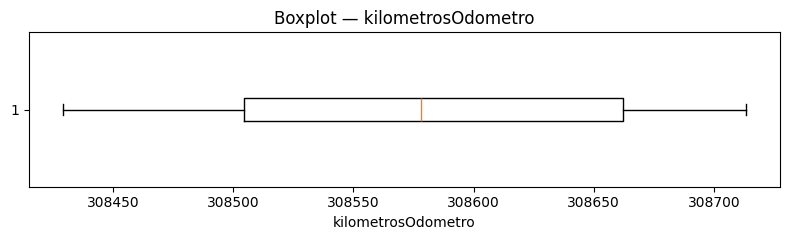

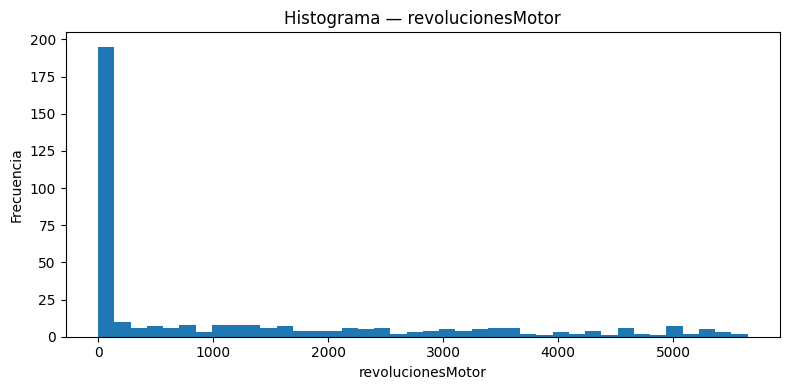

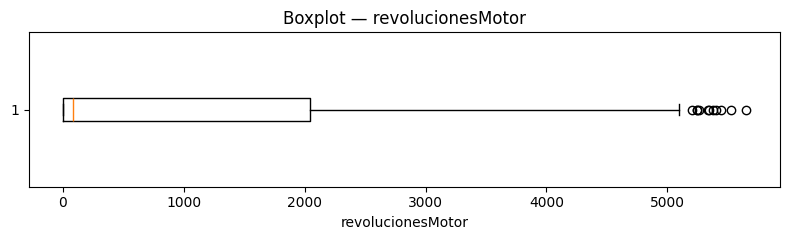

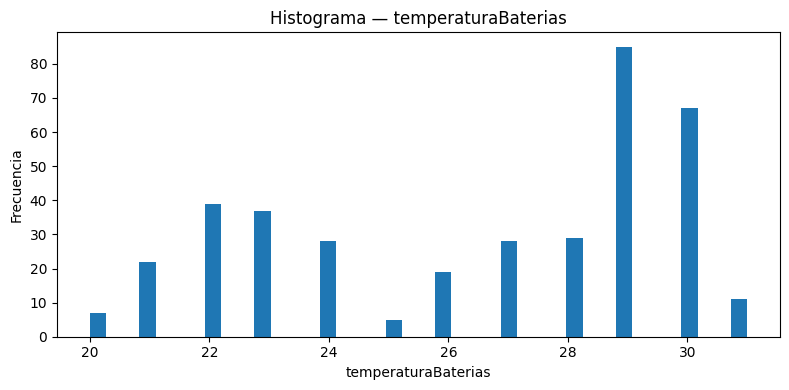

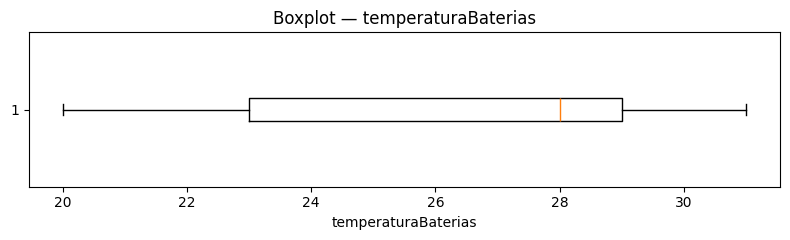

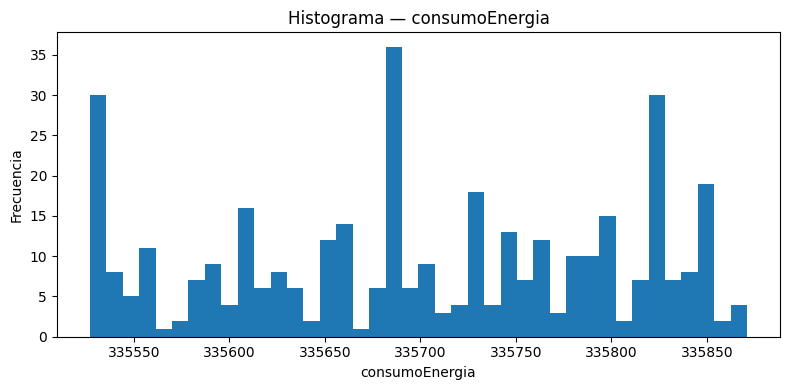

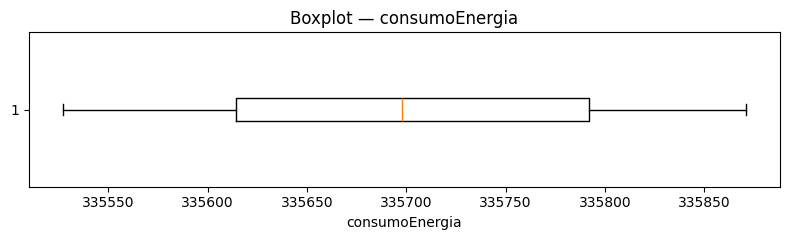

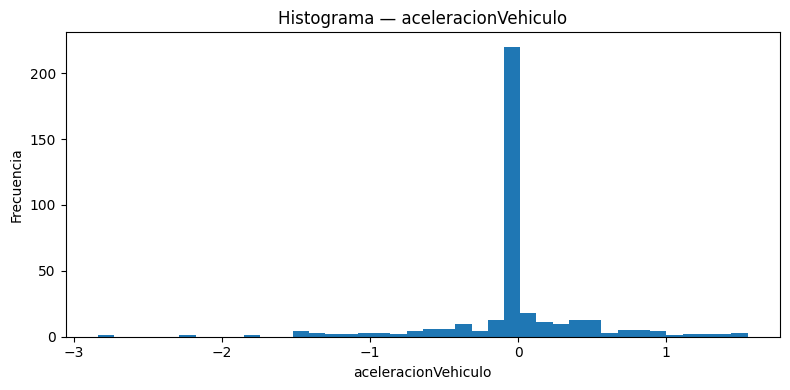

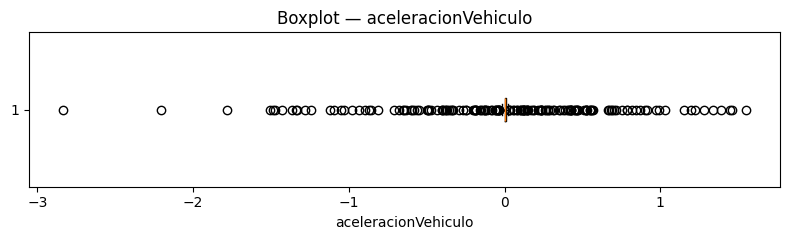

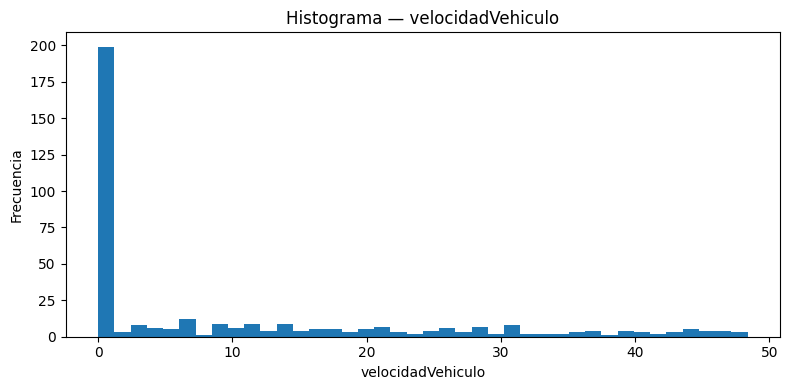

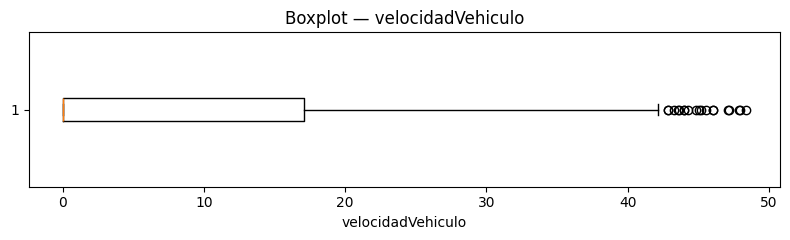

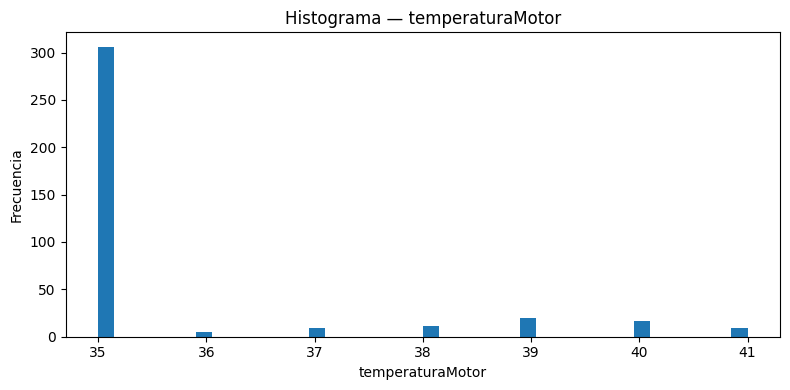

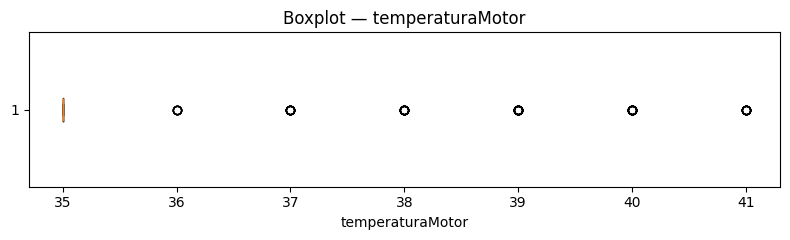

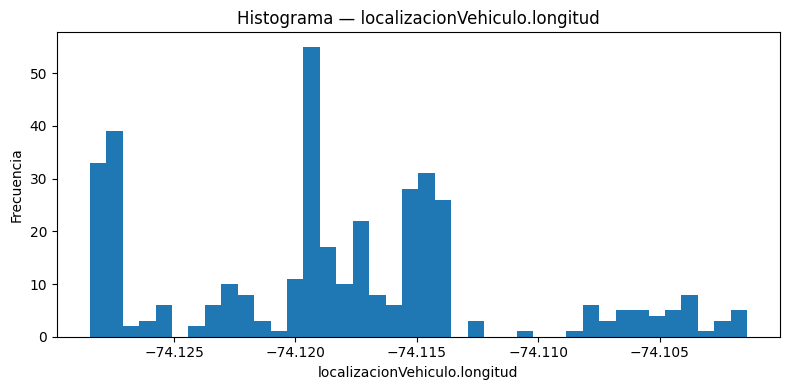

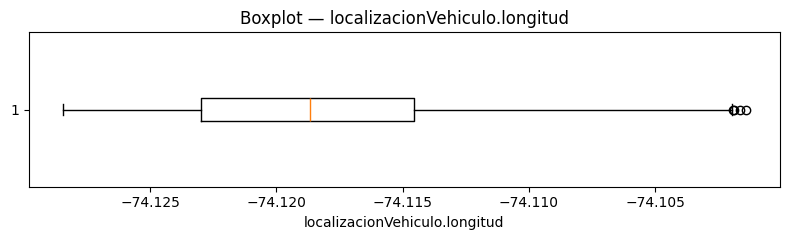

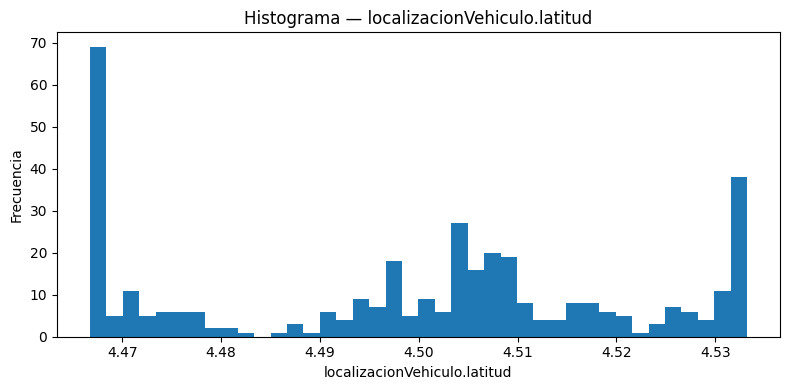

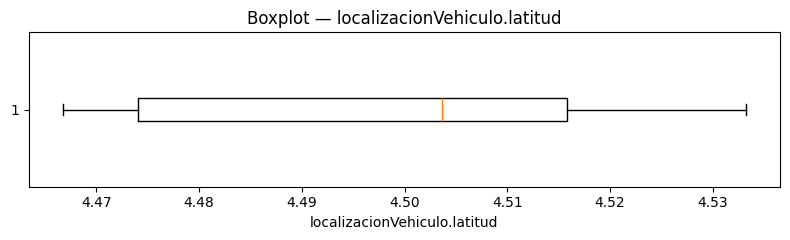

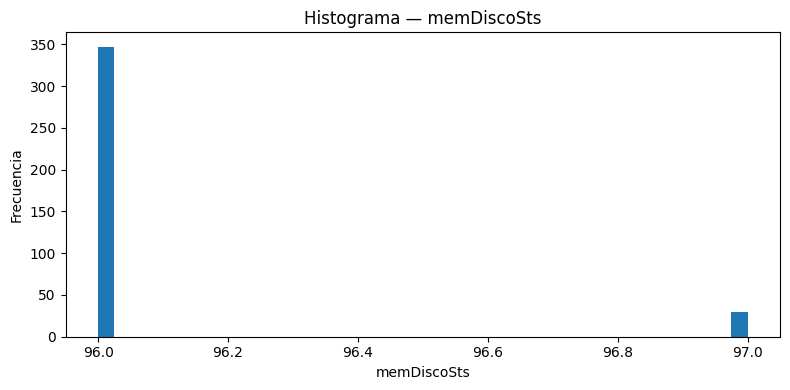

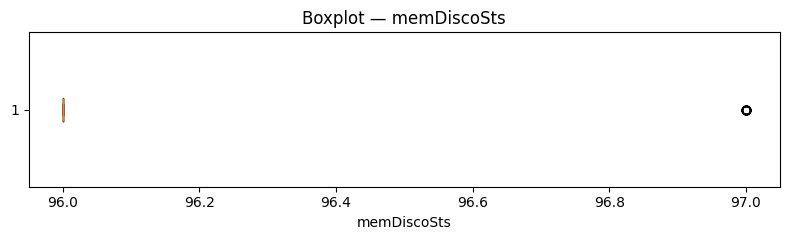

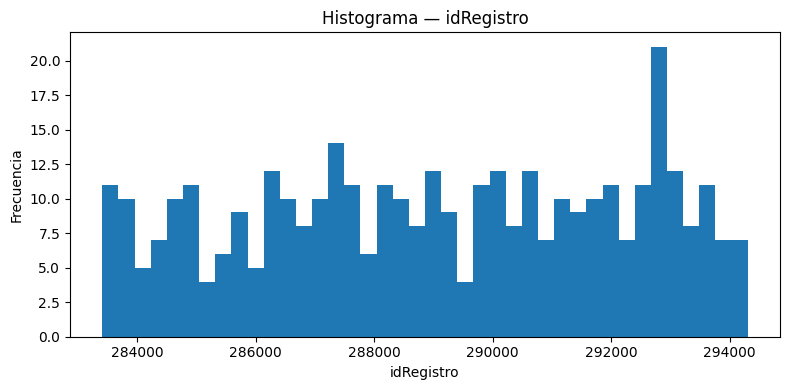

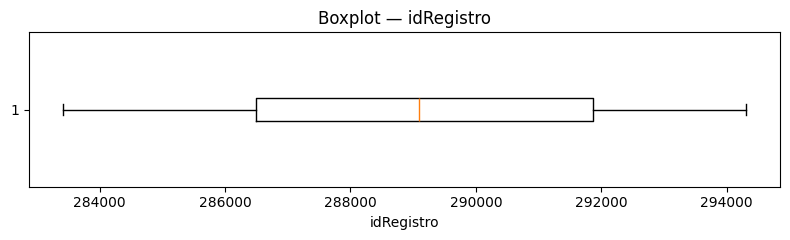

In [9]:
numericas_graficas = [
    c for c in df_limpio.select_dtypes(include='number').columns
    if df_limpio[c].nunique(dropna=True) > 1
]

if len(df_limpio) > MAX_FILAS_GRAFICOS:
    df_graf = df_limpio.sample(MAX_FILAS_GRAFICOS, random_state=SEMILLA)
else:
    df_graf = df_limpio

for col in numericas_graficas:
    serie = df_graf[col].dropna()
    if serie.empty:
        continue

    plt.figure(figsize=(8, 4))
    plt.hist(serie, bins=40)
    plt.title(f'Histograma — {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 2.5))
    plt.boxplot(serie, vert=False)
    plt.title(f'Boxplot — {col}')
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

## 4. Normalización, varianza y PCA

Los métodos basados en distancias —PCA, K-Means, DBSCAN y clustering aglomerativo— son sensibles a la escala. Por
ello se preparan dos alternativas:

- **StandardScaler:** centra en media 0 y escala a desviación estándar 1. Es adecuado cuando las distribuciones no están
  dominadas por valores extremos.
- **RobustScaler:** utiliza mediana y rango intercuartílico, por lo que es menos sensible a outliers.

Como la telemetría suele contener eventos extremos válidos, **RobustScaler se usará como matriz principal** y
StandardScaler se conserva para comparación.

### 4.1 Preparar la matriz de modelado y comparar escaladores

Se excluyen de la matriz los identificadores, la fecha y variables sin variación. `idRuta` se representa con one-hot.

Los nulos que permanezcan después del `ffill` se eliminan únicamente en esta matriz, porque PCA y clustering no aceptan
valores faltantes de forma directa.

In [10]:
# Variables numéricas candidatas.
cols_num_modelo = [
    c for c in df_limpio.select_dtypes(include='number').columns
    if df_limpio[c].nunique(dropna=True) > 1
]

# No usar identificadores numéricos si existieran con esos nombres.
excluir_modelo = {'idRegistro'}
cols_num_modelo = [c for c in cols_num_modelo if c not in excluir_modelo]

X_base = df_limpio[cols_num_modelo].copy()

# Agregar ruta one-hot solo si aporta variabilidad.
if not df_ruta_ohe.empty and df_ruta_ohe.shape[1] > 1:
    X_base = pd.concat([X_base, df_ruta_ohe], axis=1)

# Reemplazar infinitos y conservar solo filas completas para ML.
X_base = X_base.replace([np.inf, -np.inf], np.nan)
mascara_modelo = X_base.notna().all(axis=1)
X_modelo = X_base.loc[mascara_modelo].copy()

print(f'Filas originales: {len(df_limpio):,}')
print(f'Filas utilizables para modelado: {len(X_modelo):,}')
print(f'Variables de modelado: {X_modelo.shape[1]}')

if len(X_modelo) == 0:
    raise ValueError('No quedaron filas completas para construir la matriz de modelado.')

scaler_standard = StandardScaler()
scaler_robust = RobustScaler()

X_standard = scaler_standard.fit_transform(X_modelo)
X_robust = scaler_robust.fit_transform(X_modelo)

print('Matrices escaladas creadas.')

Filas originales: 377
Filas utilizables para modelado: 377
Variables de modelado: 23
Matrices escaladas creadas.


### 4.2 Análisis de varianza

La varianza ayuda a detectar variables prácticamente constantes. Después del escalamiento, una variable de varianza cero
no aporta separación entre observaciones.

Se aplica `VarianceThreshold` con umbral cero para detectar exclusivamente variables constantes; no se usa un umbral
arbitrario mayor porque podría eliminar señales pequeñas pero relevantes sin una validación posterior.

In [11]:
selector_varianza = VarianceThreshold(threshold=0.0)
selector_varianza.fit(X_modelo)

tabla_varianza = pd.DataFrame({
    'Variable': X_modelo.columns,
    'Varianza_original': X_modelo.var().values,
    'Conservar': selector_varianza.get_support()
}).sort_values('Varianza_original')

display(tabla_varianza)

variables_constantes = tabla_varianza.loc[
    ~tabla_varianza['Conservar'], 'Variable'
].tolist()

print('Variables constantes detectadas:', variables_constantes)

,Variable,Varianza_original,Conservar
14,localizacionVehiculo.longitud,0.0000,True
15,localizacionVehiculo.latitud,0.0005,True
0,sentidoMarcha,0.0027,True
21,idRuta_RET,0.0527,True
20,idRuta_No Disponible,0.0689,True
19,idRuta_DES,0.0712,True
16,memDiscoSts,0.0734,True
22,idRuta_TAP,0.0779,True
18,idRuta_3-4,0.1661,True
11,aceleracionVehiculo,0.2259,True


Variables constantes detectadas: []


### 4.3 Análisis de Componentes Principales (PCA)

PCA reduce dimensionalidad creando componentes ortogonales que concentran la mayor cantidad posible de varianza.

Se compara PCA con StandardScaler y RobustScaler. El objetivo es conocer cuántos componentes se requieren para explicar
aproximadamente el 80 %, 90 % y 95 % de la varianza. Para el clustering posterior se empleará la versión robusta.

--- StandardScaler ---
Componentes para explicar 80%: 8
Componentes para explicar 90%: 11
Componentes para explicar 95%: 13


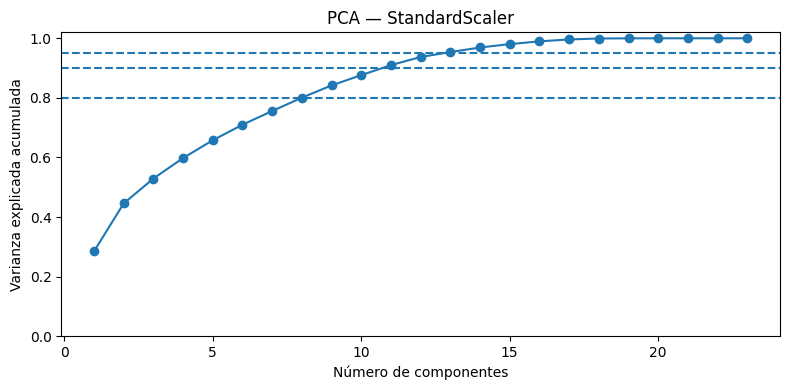

--- RobustScaler ---
Componentes para explicar 80%: 1
Componentes para explicar 90%: 1
Componentes para explicar 95%: 1


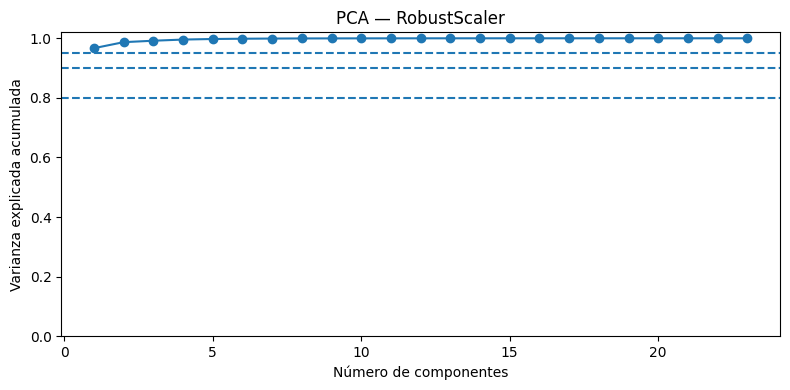

Componentes seleccionados para clustering: 2
Varianza explicada acumulada: 0.987


In [12]:
def resumen_pca(X_escalado, nombre):
    pca = PCA()
    pca.fit(X_escalado)
    acumulada = np.cumsum(pca.explained_variance_ratio_)

    def n_componentes(objetivo):
        return int(np.argmax(acumulada >= objetivo) + 1)

    print(f'--- {nombre} ---')
    for objetivo in [0.80, 0.90, 0.95]:
        print(
            f'Componentes para explicar {objetivo:.0%}: '
            f'{n_componentes(objetivo)}'
        )

    plt.figure(figsize=(8, 4))
    plt.plot(
        range(1, len(acumulada) + 1),
        acumulada,
        marker='o'
    )
    plt.axhline(0.80, linestyle='--')
    plt.axhline(0.90, linestyle='--')
    plt.axhline(0.95, linestyle='--')
    plt.xlabel('Número de componentes')
    plt.ylabel('Varianza explicada acumulada')
    plt.title(f'PCA — {nombre}')
    plt.ylim(0, 1.02)
    plt.tight_layout()
    plt.show()

    return pca, acumulada

pca_standard, acum_standard = resumen_pca(X_standard, 'StandardScaler')
pca_robust, acum_robust = resumen_pca(X_robust, 'RobustScaler')

N_COMPONENTES_PCA = int(np.argmax(acum_robust >= 0.90) + 1)
N_COMPONENTES_PCA = max(2, min(N_COMPONENTES_PCA, X_modelo.shape[1]))

pca_modelo = PCA(n_components=N_COMPONENTES_PCA)
X_pca = pca_modelo.fit_transform(X_robust)

print('Componentes seleccionados para clustering:', N_COMPONENTES_PCA)
print('Varianza explicada acumulada:',
      pca_modelo.explained_variance_ratio_.sum().round(4))

### 4.4 Comparación de componentes PCA entre rutas/grupos

Para interpretar el espacio PCA se proyectan las dos primeras componentes y se comparan por `idRuta` cuando la variable
está disponible. Esto permite observar si las rutas forman patrones diferenciables por su comportamiento telemétrico y
energético.

La visualización usa una muestra cuando existen demasiadas observaciones.

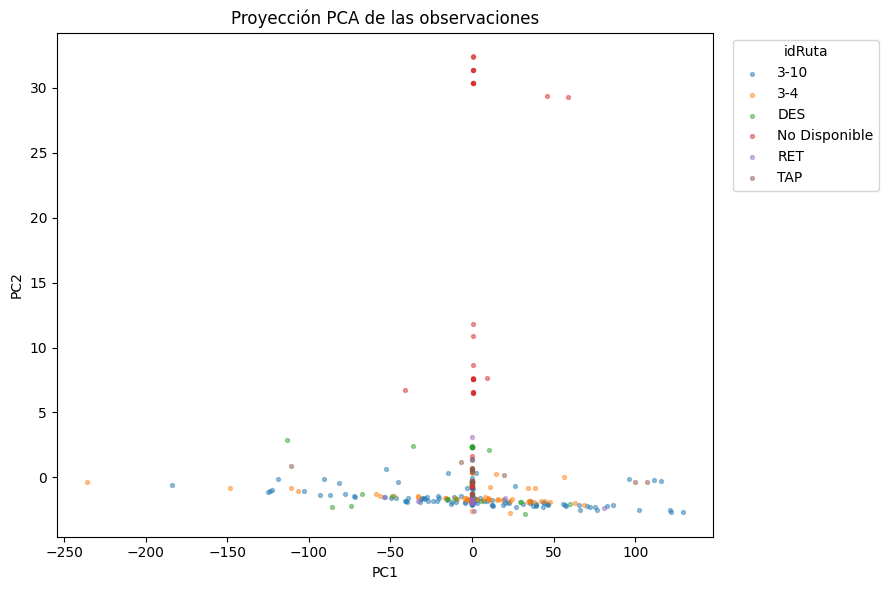

PC1                          PC2                      
                  mean median     std count    mean  median     std count
idRuta                                                                   
3-10            1.2402 0.2347 43.4764   188 -1.5819 -1.7985  0.6877   188
3-4            -1.9368 0.2300 42.7030    79 -1.4214 -1.6119  0.6122    79
DES           -10.1630 0.2516 36.9357    29  0.0751 -1.4433  2.1278    29
No Disponible   2.9016 0.3019 16.2674    28 16.0402  8.1583 12.4041    28
RET             0.8786 0.2309 23.3833    21 -1.5761 -1.7541  1.1010    21
TAP             3.5899 0.2402 32.9895    32 -0.2663 -0.3268  0.7305    32

In [13]:
df_pca = pd.DataFrame(
    X_pca[:, :min(3, X_pca.shape[1])],
    index=X_modelo.index,
    columns=[f'PC{i+1}' for i in range(min(3, X_pca.shape[1]))]
)

if 'idRuta' in df_limpio.columns:
    df_pca['idRuta'] = df_limpio.loc[df_pca.index, 'idRuta'].astype('string').fillna('SIN_RUTA')

if len(df_pca) > MAX_FILAS_GRAFICOS:
    df_pca_plot = df_pca.sample(MAX_FILAS_GRAFICOS, random_state=SEMILLA)
else:
    df_pca_plot = df_pca.copy()

plt.figure(figsize=(9, 6))

if 'idRuta' in df_pca_plot.columns and df_pca_plot['idRuta'].nunique() <= 20:
    for ruta, grupo in df_pca_plot.groupby('idRuta'):
        plt.scatter(grupo['PC1'], grupo['PC2'], s=8, alpha=0.45, label=str(ruta))
    plt.legend(title='idRuta', bbox_to_anchor=(1.02, 1), loc='upper left')
else:
    plt.scatter(df_pca_plot['PC1'], df_pca_plot['PC2'], s=8, alpha=0.45)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Proyección PCA de las observaciones')
plt.tight_layout()
plt.show()

if 'idRuta' in df_pca.columns:
    resumen_pca_ruta = (
        df_pca.groupby('idRuta')[['PC1', 'PC2']]
        .agg(['mean', 'median', 'std', 'count'])
    )
    display(resumen_pca_ruta)

## 5. Propuesta de nuevas variables: rendimiento energético

Para estudiar el rendimiento no se debe dividir directamente el odómetro acumulado entre el consumo acumulado. Se
calcula primero la **diferencia entre registros consecutivos**:

- `km_intervalo = odómetro(t) - odómetro(t-1)`
- `consumo_intervalo = consumoEnergia(t) - consumoEnergia(t-1)`
- `RendimientoTotal = km_intervalo / consumo_intervalo_kWh`

Si `consumoEnergia` está expresado en Wh, se utiliza `FACTOR_CONVERSION_KWH = 1000`. Si ya está en kWh, debe cambiarse
a 1.

Los incrementos negativos o iguales a cero se convierten en nulos porque pueden representar reinicios de contador,
errores de transmisión o periodos sin desplazamiento/consumo. Esta decisión evita rendimientos físicamente absurdos.

In [14]:
FACTOR_CONVERSION_KWH = 1000  # Cambiar a 1 si consumoEnergia ya está expresado en kWh.

df_features = df_limpio.copy()

if {'kilometrosOdometro', 'consumoEnergia'}.issubset(df_features.columns):
    if 'idVehiculo' in df_features.columns:
        grupos = df_features.groupby('idVehiculo', sort=False)
        df_features['km_intervalo'] = grupos['kilometrosOdometro'].diff()
        df_features['consumo_intervalo_raw'] = grupos['consumoEnergia'].diff()
    else:
        df_features['km_intervalo'] = df_features['kilometrosOdometro'].diff()
        df_features['consumo_intervalo_raw'] = df_features['consumoEnergia'].diff()

    df_features['consumo_intervalo_kWh'] = (
        df_features['consumo_intervalo_raw'] / FACTOR_CONVERSION_KWH
    )

    # Validaciones físicas básicas.
    df_features.loc[df_features['km_intervalo'] <= 0, 'km_intervalo'] = np.nan
    df_features.loc[
        df_features['consumo_intervalo_kWh'] <= 0,
        'consumo_intervalo_kWh'
    ] = np.nan

    df_features['RendimientoTotal_km_kWh'] = (
        df_features['km_intervalo'] /
        df_features['consumo_intervalo_kWh']
    )

    df_features['RendimientoTotal_km_kWh'] = (
        df_features['RendimientoTotal_km_kWh']
        .replace([np.inf, -np.inf], np.nan)
    )

    print('Variable RendimientoTotal_km_kWh creada.')
    display(
        df_features[
            [
                'kilometrosOdometro',
                'consumoEnergia',
                'km_intervalo',
                'consumo_intervalo_kWh',
                'RendimientoTotal_km_kWh'
            ]
        ].describe().T
    )
else:
    print(
        'No se pudo crear RendimientoTotal: faltan '
        'kilometrosOdometro y/o consumoEnergia.'
    )

Variable RendimientoTotal_km_kWh creada.


,count,mean,std,min,25%,50%,75%,max
kilometrosOdometro,377.0000,"308,579.4153",86.6840,"308,428.9750","308,504.2550","308,578.3150","308,662.1750","308,713.3550"
consumoEnergia,377.0000,"335,700.8568",101.8730,"335,527.0000","335,614.0000","335,698.0000","335,792.0000","335,871.0000"
km_intervalo,304.0000,0.9355,1.1722,0.0050,0.1500,0.4675,1.3087,8.6600
consumo_intervalo_kWh,146.0000,0.0028,0.0025,0.0010,0.0010,0.0020,0.0040,0.0130
RendimientoTotal_km_kWh,142.0000,514.1102,641.7003,10.0000,256.2500,335.0000,537.6389,"5,250.0000"


### 5.1 Revisión de valores extremos del rendimiento

Los rendimientos calculados entre tramas pueden amplificarse cuando la distancia o el consumo del intervalo son muy
pequeños. En lugar de eliminarlos silenciosamente, se calcula el rango intercuartílico (IQR) y se crea una marca de
atípico para análisis posterior.

In [15]:
if 'RendimientoTotal_km_kWh' in df_features.columns:
    serie_rend = df_features['RendimientoTotal_km_kWh'].dropna()

    if not serie_rend.empty:
        q1 = serie_rend.quantile(0.25)
        q3 = serie_rend.quantile(0.75)
        iqr = q3 - q1
        lim_inf = q1 - 1.5 * iqr
        lim_sup = q3 + 1.5 * iqr

        df_features['Rendimiento_atipico_IQR'] = (
            (df_features['RendimientoTotal_km_kWh'] < lim_inf) |
            (df_features['RendimientoTotal_km_kWh'] > lim_sup)
        )

        print('Límite inferior IQR:', lim_inf)
        print('Límite superior IQR:', lim_sup)
        print(
            'Atípicos detectados:',
            int(df_features['Rendimiento_atipico_IQR'].sum())
        )

Límite inferior IQR: -165.8333333277065
Límite superior IQR: 959.7222222154312
Atípicos detectados: 15


## 6. Exploración de clusters

Para evitar que un dataset muy grande haga lenta la fase exploratoria, el clustering usa una muestra máxima
reproducible. Se trabaja sobre la representación PCA robusta, que reduce ruido, escala y dimensionalidad.

Los clusters **no son todavía clases reales**: son agrupaciones exploratorias que luego deben interpretarse con las
variables originales, rutas, horarios y condiciones de operación.

In [16]:
# Dataset de clustering sobre PCA.
if len(X_pca) > MAX_FILAS_CLUSTER:
    rng = np.random.default_rng(SEMILLA)
    idx_cluster_pos = np.sort(
        rng.choice(len(X_pca), size=MAX_FILAS_CLUSTER, replace=False)
    )
else:
    idx_cluster_pos = np.arange(len(X_pca))

X_cluster = X_pca[idx_cluster_pos]
indices_originales_cluster = X_modelo.index[idx_cluster_pos]

print('Observaciones usadas en clustering:', len(X_cluster))
print('Dimensiones PCA:', X_cluster.shape[1])

Observaciones usadas en clustering: 377
Dimensiones PCA: 2


### 6.1 K-Means: Elbow Method y Silhouette

El método del codo compara la inercia para distintos valores de `k`. Silhouette evalúa simultáneamente cohesión dentro
del cluster y separación entre clusters; valores más altos son preferibles.

Se exploran valores de `k` entre 2 y 10, siempre que el número de observaciones lo permita. El mejor `k` por Silhouette
se utiliza para el modelo exploratorio.

,k,Inercia,Silhouette
0,2,"309,804.0384",0.7229
1,3,"140,368.5896",0.7198
2,4,"95,823.9193",0.7145
3,5,"64,647.7655",0.7185
4,6,"46,433.1986",0.7229
5,7,"37,474.7042",0.7139
6,8,"28,610.6989",0.7431
7,9,"21,517.2004",0.7426
8,10,"17,624.3688",0.7043


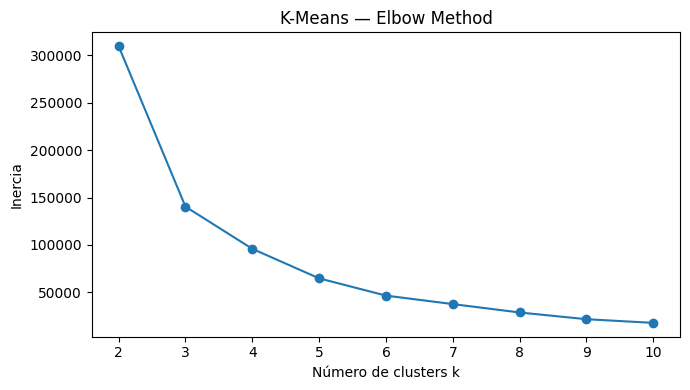

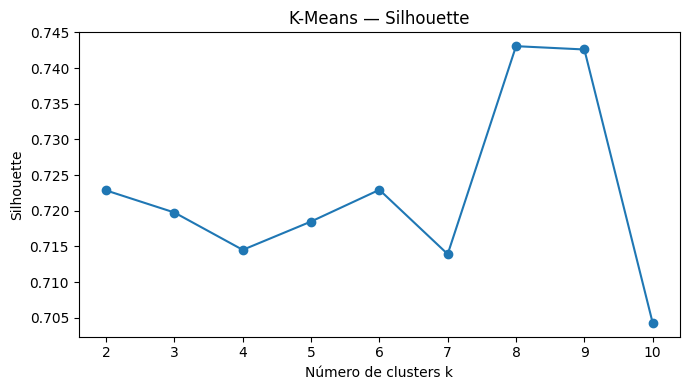

K óptimo según Silhouette: 8
0    250
1     19
2     17
3      2
4     40
5     31
6      9
7      9
Name: count, dtype: int64


In [17]:
max_k = min(10, len(X_cluster) - 1)
ks = list(range(2, max_k + 1))

inercias = []
silhouettes = []

# Para Silhouette, evaluar un máximo de 10.000 observaciones reduce tiempo.
if len(X_cluster) > 10_000:
    rng = np.random.default_rng(SEMILLA)
    idx_sil = rng.choice(len(X_cluster), 10_000, replace=False)
    X_sil = X_cluster[idx_sil]
else:
    idx_sil = np.arange(len(X_cluster))
    X_sil = X_cluster

for k in ks:
    modelo = KMeans(
        n_clusters=k,
        random_state=SEMILLA,
        n_init=10
    )
    etiquetas = modelo.fit_predict(X_cluster)
    inercias.append(modelo.inertia_)

    # Silhouette se calcula sobre la misma partición en una muestra.
    etiquetas_sil = etiquetas[idx_sil]
    if len(np.unique(etiquetas_sil)) > 1:
        silhouettes.append(silhouette_score(X_sil, etiquetas_sil))
    else:
        silhouettes.append(np.nan)

resultados_k = pd.DataFrame({
    'k': ks,
    'Inercia': inercias,
    'Silhouette': silhouettes
})
display(resultados_k)

plt.figure(figsize=(7, 4))
plt.plot(ks, inercias, marker='o')
plt.xlabel('Número de clusters k')
plt.ylabel('Inercia')
plt.title('K-Means — Elbow Method')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(ks, silhouettes, marker='o')
plt.xlabel('Número de clusters k')
plt.ylabel('Silhouette')
plt.title('K-Means — Silhouette')
plt.tight_layout()
plt.show()

K_OPTIMO = int(resultados_k.loc[
    resultados_k['Silhouette'].idxmax(), 'k'
])

kmeans = KMeans(
    n_clusters=K_OPTIMO,
    random_state=SEMILLA,
    n_init=20
)
labels_kmeans = kmeans.fit_predict(X_cluster)

print('K óptimo según Silhouette:', K_OPTIMO)
print(pd.Series(labels_kmeans).value_counts().sort_index())

### 6.2 Visualización e interpretación inicial de K-Means

Se proyectan los clusters sobre las dos primeras componentes principales y luego se resumen las variables originales
por cluster. Esta segunda tabla es importante: el número de cluster por sí solo no tiene significado físico.

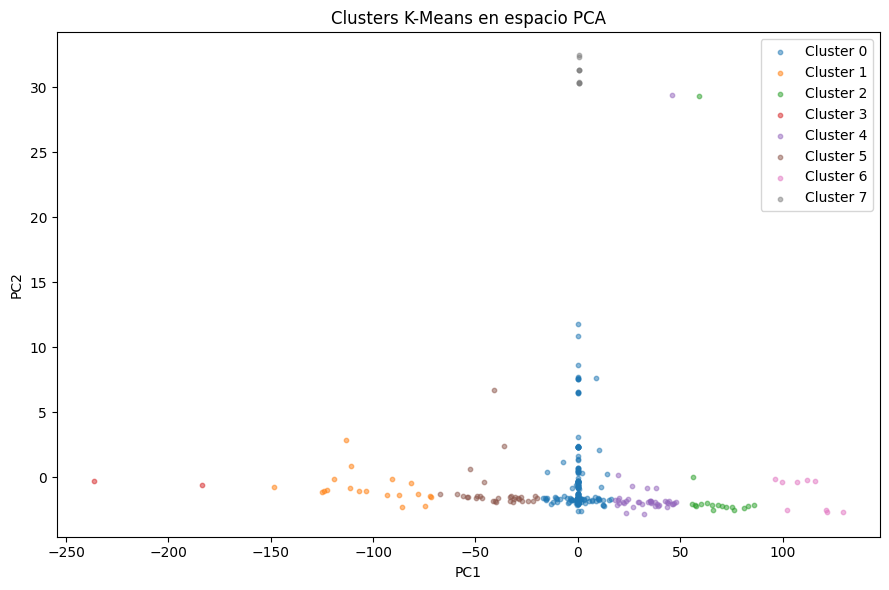

kilometrosOdometro                            consumoEnergia  \
                             mean       median     std count           mean   
Cluster_KMeans                                                                
0                    308,580.6940 308,573.0225 85.6803   250   335,702.3280   
1                    308,590.5021 308,598.1050 82.2072    19   335,714.5789   
2                    308,599.2856 308,620.4850 90.6211    17   335,724.8824   
3                    308,536.6625 308,536.6625 66.6837     2   335,649.5000   
4                    308,569.9344 308,590.7300 87.9009    40   335,689.4500   
5                    308,600.0631 308,625.2100 75.4158    31   335,723.9032   
6                    308,613.9139 308,578.6000 54.3134     9   335,740.4444   
7                    308,428.9750 308,428.9750  0.0000     9   335,528.7778   

                                           regeneracionEnergia               \
                     median      std count                mean       median   
Cluster_KMeans                                                                
0              335,690.0000 101.0760   250        239,658.4200 239,646.5000   
1              335,724.0000  98.6207    19        239,666.5789 239,668.0000   
2              335,748.0000 105.7384    17        239,675.4118 239,692.0000   
3              335,649.5000  81.3173     2        239,616.5000 239,616.5000   
4              335,714.0000 102.7529    40        239,649.1000 239,662.0000   
5              335,751.0000  88.0929    31        239,675.5161 239,697.0000   
6              335,698.0000  62.9069     9        239,685.8889 239,650.0000   
7              335,529.0000   0.6667     9        239,534.0000 239,534.0000   

                             nivelRestanteEnergia                         \
                   std count                 mean   median     std count   
Cluster_KMeans                                                             
0              75.5851   250              62.7760  62.5000 22.0821   250   
1              72.4694    19              62.0526  66.0000 24.8473    19   
2              80.0883    17              63.0000  66.0000 21.9460    17   
3              54.4472     2              81.0000  81.0000 14.1421     2   
4              77.2853    40              65.8750  69.5000 19.1488    40   
5              67.0964    31              63.8065  58.0000 19.5234    31   
6              51.1479     9              61.3333  58.0000 26.7955     9   
7               0.0000     9             100.0000 100.0000  0.0000     9   

               km_intervalo                     consumo_intervalo_kWh         \
                       mean median    std count                  mean median   
Cluster_KMeans                                                                 
0                    0.9289 0.3900 1.2348   186                0.0029 0.0010   
1                    1.1174 0.9600 0.9242    19                0.0030 0.0030   
2                    0.7850 0.6600 0.7902    17                0.0019 0.0020   
3                    0.4675 0.4675 0.1237     2                0.0010 0.0010   
4                    0.9292 0.5825 0.8716    40                0.0032 0.0030   
5                    1.0145 0.5900 1.5679    31                0.0025 0.0020   
6                    0.8306 0.5850 0.6848     9                0.0018 0.0010   
7                       NaN    NaN    NaN     0                   NaN    NaN   

                            RendimientoTotal_km_kWh                          
                  std count                    mean   median      std count  
Cluster_KMeans                                                               
0              0.0029    85                492.7980 326.0000 670.8411    81  
1              0.0022     9                581.5509 349.3750 441.3784     9  
2              0.0006     8                545.4167 306.6667 517.0788     8  
3                 NaN     1                555.0000 555.0000      NaN     1  
4          

In [18]:
df_cluster_resultado = df_features.loc[
    indices_originales_cluster
].copy()

df_cluster_resultado['Cluster_KMeans'] = labels_kmeans
df_cluster_resultado['PC1'] = X_cluster[:, 0]
df_cluster_resultado['PC2'] = X_cluster[:, 1]

plt.figure(figsize=(9, 6))
for cluster, grupo in df_cluster_resultado.groupby('Cluster_KMeans'):
    plt.scatter(
        grupo['PC1'],
        grupo['PC2'],
        s=10,
        alpha=0.5,
        label=f'Cluster {cluster}'
    )
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters K-Means en espacio PCA')
plt.legend()
plt.tight_layout()
plt.show()

columnas_resumen_cluster = [
    c for c in [
        'kilometrosOdometro',
        'consumoEnergia',
        'regeneracionEnergia',
        'nivelRestanteEnergia',
        'km_intervalo',
        'consumo_intervalo_kWh',
        'RendimientoTotal_km_kWh'
    ]
    if c in df_cluster_resultado.columns
]

if columnas_resumen_cluster:
    resumen_cluster = (
        df_cluster_resultado
        .groupby('Cluster_KMeans')[columnas_resumen_cluster]
        .agg(['mean', 'median', 'std', 'count'])
    )
    display(resumen_cluster)

### 6.3 DBSCAN

DBSCAN puede detectar grupos de forma no esférica y marcar observaciones aisladas como ruido (`-1`). A diferencia de
K-Means, no exige indicar el número de clusters, pero sí requiere elegir `eps` y `min_samples`.

Para evitar asignar un `eps` arbitrario, se calcula la distancia al vecino número `min_samples`. El cuaderno propone
como valor inicial el percentil 90 de esas distancias. **Debe considerarse un punto de partida experimental**, no un
hiperparámetro definitivo.

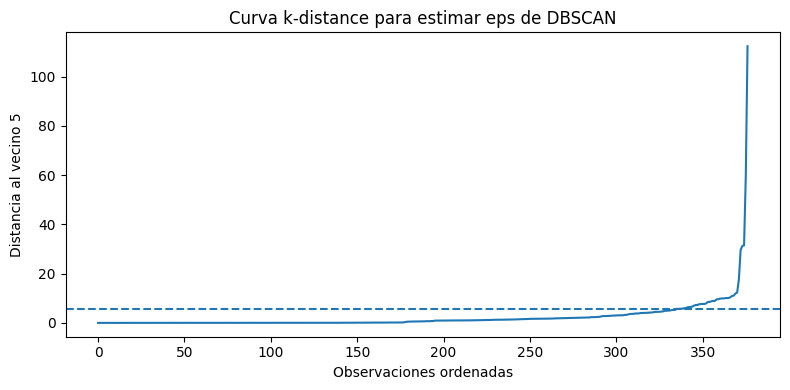

min_samples: 5
eps inicial sugerido: 5.8202


,Registros
-1,29
0,9
1,318
2,16
3,5


Clusters DBSCAN encontrados: 4
Porcentaje de ruido: 7.69 %
Silhouette DBSCAN sin ruido: 0.5282


In [19]:
if len(X_cluster) > MAX_FILAS_DBSCAN:
    rng = np.random.default_rng(SEMILLA)
    idx_db = np.sort(
        rng.choice(len(X_cluster), MAX_FILAS_DBSCAN, replace=False)
    )
    X_db = X_cluster[idx_db]
else:
    idx_db = np.arange(len(X_cluster))
    X_db = X_cluster

MIN_SAMPLES_DBSCAN = max(5, 2 * X_db.shape[1])

vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES_DBSCAN)
vecinos.fit(X_db)
distancias, _ = vecinos.kneighbors(X_db)

k_distancias = np.sort(distancias[:, -1])
EPS_SUGERIDO = float(np.percentile(k_distancias, 90))

plt.figure(figsize=(8, 4))
plt.plot(k_distancias)
plt.axhline(EPS_SUGERIDO, linestyle='--')
plt.xlabel('Observaciones ordenadas')
plt.ylabel(f'Distancia al vecino {MIN_SAMPLES_DBSCAN}')
plt.title('Curva k-distance para estimar eps de DBSCAN')
plt.tight_layout()
plt.show()

print('min_samples:', MIN_SAMPLES_DBSCAN)
print('eps inicial sugerido:', round(EPS_SUGERIDO, 4))

dbscan = DBSCAN(
    eps=EPS_SUGERIDO,
    min_samples=MIN_SAMPLES_DBSCAN
)
labels_dbscan = dbscan.fit_predict(X_db)

conteo_dbscan = pd.Series(labels_dbscan).value_counts().sort_index()
display(conteo_dbscan.rename('Registros').to_frame())

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
porcentaje_ruido = (labels_dbscan == -1).mean() * 100

print('Clusters DBSCAN encontrados:', n_clusters_dbscan)
print('Porcentaje de ruido:', round(porcentaje_ruido, 2), '%')

if n_clusters_dbscan >= 2:
    mascara_no_ruido = labels_dbscan != -1
    if mascara_no_ruido.sum() > 2_000:
        rng = np.random.default_rng(SEMILLA)
        candidatos = np.where(mascara_no_ruido)[0]
        muestra_sil_db = rng.choice(candidatos, 2_000, replace=False)
    else:
        muestra_sil_db = np.where(mascara_no_ruido)[0]

    if len(np.unique(labels_dbscan[muestra_sil_db])) >= 2:
        sil_db = silhouette_score(
            X_db[muestra_sil_db],
            labels_dbscan[muestra_sil_db]
        )
        print('Silhouette DBSCAN sin ruido:', round(sil_db, 4))

## 7. Análisis experimental de la matriz transpuesta

### ¿Conviene transponer el dataset original?

**No es recomendable transponer directamente todas las tramas.** En el dataset original las filas representan momentos
y las columnas representan variables. Al transponerlo, cada variable tendría decenas de miles de dimensiones
temporales, lo que aumenta el costo computacional y dificulta la interpretación.

Para que la idea sea útil, se construye una versión experimental más compacta:

1. Agrupar por `idRuta`.
2. Calcular la media de variables numéricas por ruta.
3. Estandarizar esos perfiles.
4. Transponer la matriz para que cada fila represente una **variable** y cada columna una **ruta**.

Así, el clustering transpuesto busca variables que se comportan de forma parecida entre rutas. Esto complementa, pero no
reemplaza, el clustering de observaciones.

### 7.1 Construcción de perfiles y transposición

In [20]:
if 'idRuta' in df_features.columns:
    num_trans = [
        c for c in df_features.select_dtypes(include='number').columns
        if df_features[c].nunique(dropna=True) > 1
        and c not in ['Rendimiento_atipico_IQR']
    ]

    perfiles_ruta = (
        df_features
        .groupby('idRuta', dropna=False)[num_trans]
        .mean()
    )

    # Eliminar columnas con demasiados nulos en el perfil.
    perfiles_ruta = perfiles_ruta.dropna(axis=1, how='all')

    # Relleno de nulos residuales con la mediana de cada variable, únicamente
    # para poder comparar perfiles agregados.
    perfiles_ruta = perfiles_ruta.apply(
        lambda s: s.fillna(s.median()),
        axis=0
    )

    print('Matriz de perfiles por ruta:', perfiles_ruta.shape)
    display(perfiles_ruta.head())

    # Escalar cada variable antes de transponer.
    scaler_trans = StandardScaler()
    perfiles_escalados = pd.DataFrame(
        scaler_trans.fit_transform(perfiles_ruta),
        index=perfiles_ruta.index,
        columns=perfiles_ruta.columns
    )

    X_transpuesta = perfiles_escalados.T
    print('Matriz transpuesta (variables x rutas):', X_transpuesta.shape)
    display(X_transpuesta.head())
else:
    perfiles_ruta = None
    X_transpuesta = None
    print('No existe idRuta; no se construye la transposición experimental.')

Matriz de perfiles por ruta: (6, 22)


,sentidoMarcha,memRamSts,usoCpuSts,temperaturaSts,regeneracionEnergia,nivelRestanteEnergia,estadoDesgasteFrenos,kilometrosOdometro,revolucionesMotor,temperaturaBaterias,consumoEnergia,aceleracionVehiculo,velocidadVehiculo,temperaturaMotor,localizacionVehiculo.longitud,localizacionVehiculo.latitud,memDiscoSts,idRegistro,km_intervalo,consumo_intervalo_raw,consumo_intervalo_kWh,RendimientoTotal_km_kWh
idRuta,,,,,,,,,,,,,,,,,,,,,,
3-10,0.0053,1.2128,3.4309,40.7713,"239,717.1755",59.4628,40.1277,"308,647.6639","1,207.2128",28.8351,"335,780.8830",0.0120,10.2967,36.2819,-74.1193,4.4962,96.0000,"291,543.2287",0.7608,1.0000,0.0025,478.5159
3-4,0.0000,1.1772,2.8228,35.5823,"239,570.6456",73.3924,40.1772,"308,481.2264","1,590.5190",21.8481,"335,586.4051",-0.0260,13.8610,35.0127,-74.1119,4.5110,96.0380,"285,663.3671",0.9996,1.5316,0.0036,440.0076
DES,0.0000,2.6897,2.5517,33.8966,"239,621.9655",44.3448,40.2414,"308,540.7086","1,737.0690",23.5862,"335,655.5517",-0.1249,15.1961,35.0000,-74.1137,4.5168,96.0000,"287,416.5517",1.4280,0.6552,0.0030,299.4537
No Disponible,0.0000,18.3929,3.2500,28.1071,"239,556.0000",93.5000,42.7143,"308,455.3887",150.6607,27.7143,"335,558.6071",0.0308,1.3623,35.0000,-74.1270,4.4742,96.8929,"284,664.7500",1.3288,0.1481,0.0014,"1,585.0000"
RET,0.0000,1.1429,3.7619,39.0000,"239,659.0952",65.7619,40.1905,"308,580.0614",661.5952,25.9524,"335,697.0476",0.0077,5.8214,36.5714,-74.1183,4.5273,96.0952,"289,112.8095",1.2759,-0.3810,0.0010,"1,391.0000"


Matriz transpuesta (variables x rutas): (22, 6)


idRuta,3-10,3-4,DES,No Disponible,RET,TAP
sentidoMarcha,2.2361,-0.4472,-0.4472,-0.4472,-0.4472,-0.4472
memRamSts,-0.5193,-0.5250,-0.2833,2.2265,-0.5305,-0.3685
usoCpuSts,0.7593,-0.1400,-0.5409,0.4918,1.2490,-1.8192
temperaturaSts,1.2808,-0.0047,-0.4223,-1.8565,0.8420,0.1607
regeneracionEnergia,1.6530,-1.0526,-0.1050,-1.3230,0.5806,0.2470


### 7.2 PCA sobre la matriz transpuesta

En este PCA las observaciones son **variables**, no tramas. La pregunta cambia: ¿qué variables muestran perfiles
semejantes o distintos entre las rutas?

El número máximo de componentes queda limitado por la cantidad de variables y rutas disponibles.

Varianza explicada acumulada PCA transpuesta: 1.0


,PC1,PC2,PC3,PC4,PC5
sentidoMarcha,-0.7553,-0.9830,0.1460,-1.4474,0.4254
memRamSts,2.4910,0.5871,-0.4819,-0.3367,0.8191
usoCpuSts,0.3057,-0.8808,-2.0363,-0.0998,-0.0335
temperaturaSts,-1.6491,-0.7449,0.2896,0.2304,-0.7727
regeneracionEnergia,-1.2414,-1.2970,0.6297,0.1458,0.2779
nivelRestanteEnergia,2.2959,0.4173,-0.8136,-0.6115,-0.7765
estadoDesgasteFrenos,2.1676,0.6377,1.5043,0.2465,0.0691
kilometrosOdometro,-1.3125,-1.2164,0.6850,0.1754,0.2484
revolucionesMotor,-1.7947,1.6591,-0.4452,-0.2035,0.3713
temperaturaBaterias,1.0780,-1.5660,0.4705,-0.4880,0.6779


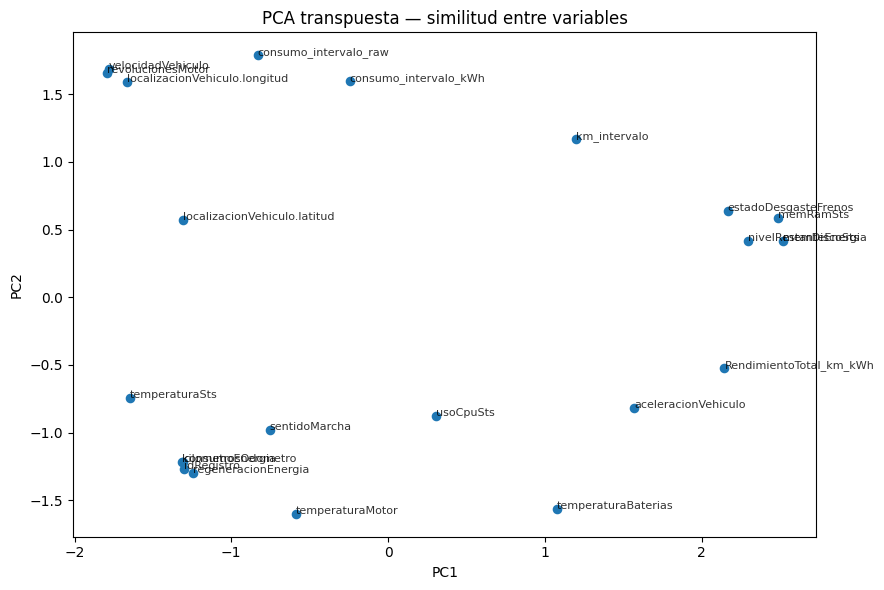

In [21]:
if X_transpuesta is not None and min(X_transpuesta.shape) >= 2:
    n_pca_t = min(5, X_transpuesta.shape[0], X_transpuesta.shape[1])

    pca_t = PCA(n_components=n_pca_t)
    X_pca_t = pca_t.fit_transform(X_transpuesta)

    df_pca_t = pd.DataFrame(
        X_pca_t,
        index=X_transpuesta.index,
        columns=[f'PC{i+1}' for i in range(n_pca_t)]
    )

    print(
        'Varianza explicada acumulada PCA transpuesta:',
        round(pca_t.explained_variance_ratio_.sum(), 4)
    )
    display(df_pca_t)

    if n_pca_t >= 2:
        plt.figure(figsize=(9, 6))
        plt.scatter(df_pca_t['PC1'], df_pca_t['PC2'], s=35)
        for variable, fila in df_pca_t.iterrows():
            plt.annotate(
                variable,
                (fila['PC1'], fila['PC2']),
                fontsize=8,
                alpha=0.8
            )
        plt.xlabel('PC1')
        plt.ylabel('PC2')
        plt.title('PCA transpuesta — similitud entre variables')
        plt.tight_layout()
        plt.show()
else:
    X_pca_t = None
    df_pca_t = None
    print('No hay dimensiones suficientes para PCA transpuesta.')

### 7.3 Clustering sobre la matriz transpuesta

Este clustering agrupa **variables con perfiles similares entre rutas**. Se utiliza K-Means solo si existe un número
suficiente de variables para formar más de un grupo.

In [22]:
if X_pca_t is not None and len(X_pca_t) >= 4:
    max_k_t = min(6, len(X_pca_t) - 1)
    resultados_t = []

    for k in range(2, max_k_t + 1):
        km_t = KMeans(n_clusters=k, random_state=SEMILLA, n_init=20)
        labels_t = km_t.fit_predict(X_pca_t)
        sil_t = silhouette_score(X_pca_t, labels_t)
        resultados_t.append({
            'k': k,
            'Inercia': km_t.inertia_,
            'Silhouette': sil_t
        })

    resultados_t = pd.DataFrame(resultados_t)
    display(resultados_t)

    k_t_optimo = int(
        resultados_t.loc[resultados_t['Silhouette'].idxmax(), 'k']
    )

    kmeans_t = KMeans(
        n_clusters=k_t_optimo,
        random_state=SEMILLA,
        n_init=20
    )
    labels_t = kmeans_t.fit_predict(X_pca_t)

    resultado_variables = pd.DataFrame({
        'Variable': X_transpuesta.index,
        'Cluster_variable': labels_t
    }).sort_values(['Cluster_variable', 'Variable'])

    print('K óptimo transpuesto:', k_t_optimo)
    display(resultado_variables)
else:
    print('No hay suficientes variables para clustering transpuesto.')

,k,Inercia,Silhouette
0,2,77.1665,0.3315
1,3,52.5710,0.3753
2,4,38.7833,0.3985
3,5,31.9506,0.3793
4,6,25.5934,0.3962


K óptimo transpuesto: 4


,Variable,Cluster_variable
19,consumo_intervalo_raw,0
15,localizacionVehiculo.latitud,0
14,localizacionVehiculo.longitud,0
8,revolucionesMotor,0
12,velocidadVehiculo,0
21,RendimientoTotal_km_kWh,1
11,aceleracionVehiculo,1
16,memDiscoSts,1
1,memRamSts,1
5,nivelRestanteEnergia,1


### 7.4 Reducción adicional de dimensionalidad — bloque opcional

Este bloque se deja **comentado** porque PCA ya realiza reducción dimensional. Solo conviene probar métodos adicionales
si los resultados de PCA/K-Means/DBSCAN muestran una estructura difícil de separar.

UMAP o t-SNE pueden ser útiles para visualización no lineal, pero no deben interpretarse como sustitutos directos de
PCA ni ejecutarse sobre millones de observaciones sin muestreo.

In [23]:
# BLOQUE OPCIONAL — EJECUTAR SOLO SI SE REQUIERE
#
# !pip -q install umap-learn
# import umap.umap_ as umap
#
# reducer = umap.UMAP(
#     n_components=2,
#     n_neighbors=30,
#     min_dist=0.1,
#     random_state=SEMILLA
# )
#
# # Se recomienda usar X_cluster o una muestra, no el dataset completo.
# X_umap = reducer.fit_transform(X_cluster)
#
# plt.figure(figsize=(9, 6))
# plt.scatter(X_umap[:, 0], X_umap[:, 1], s=8, alpha=0.5)
# plt.xlabel('UMAP 1')
# plt.ylabel('UMAP 2')
# plt.title('Reducción no lineal UMAP — exploratoria')
# plt.tight_layout()
# plt.show()

### 7.5 Matriz de correlación de perfiles transpuestos/reducidos

Una correlación directa después de transponer el dataset completo no sería comparable con la correlación entre
observaciones originales. Aquí se calcula la correlación **entre variables a partir de sus perfiles medios por ruta**.

Valores altos indican que dos variables cambian de forma similar entre rutas, aunque esto no demuestra causalidad.

,sentidoMarcha,memRamSts,usoCpuSts,temperaturaSts,regeneracionEnergia,nivelRestanteEnergia,estadoDesgasteFrenos,kilometrosOdometro,revolucionesMotor,temperaturaBaterias,consumoEnergia,aceleracionVehiculo,velocidadVehiculo,temperaturaMotor,localizacionVehiculo.longitud,localizacionVehiculo.latitud,memDiscoSts,idRegistro,km_intervalo,consumo_intervalo_raw,consumo_intervalo_kWh,RendimientoTotal_km_kWh
sentidoMarcha,1.0000,-0.2320,0.3400,0.5730,0.7390,-0.1950,-0.3340,0.7230,0.1700,0.6010,0.7390,0.1780,0.1520,0.5320,-0.0190,-0.0780,-0.2360,0.7480,-0.7010,0.3060,-0.1160,-0.2760
memRamSts,-0.2320,1.0000,0.1560,-0.8640,-0.6030,0.7670,0.5870,-0.6390,-0.6450,0.3680,-0.6290,0.2780,-0.6390,-0.3710,-0.6690,-0.5720,0.9850,-0.6330,0.1600,-0.3260,-0.3800,0.6720
usoCpuSts,0.3400,0.1560,1.0000,0.1750,0.1810,0.3370,-0.5370,0.1420,-0.1310,0.3330,0.1420,0.0960,-0.1310,0.7230,0.0680,0.4580,0.2840,0.1940,-0.6830,-0.3400,-0.9340,0.5550
temperaturaSts,0.5730,-0.8640,0.1750,1.0000,0.8590,-0.5700,-0.5550,0.8720,0.3470,0.1030,0.8650,0.0720,0.3350,0.7310,0.3740,0.4420,-0.8100,0.8850,-0.3880,0.1350,0.1110,-0.3980
regeneracionEnergia,0.7390,-0.6030,0.1810,0.8590,1.0000,-0.6020,-0.3490,0.9990,0.1390,0.4970,0.9990,0.1020,0.1250,0.7440,0.0370,0.1930,-0.5990,0.9980,-0.2750,-0.0840,0.0100,-0.2850
nivelRestanteEnergia,-0.1950,0.7670,0.3370,-0.5700,-0.6020,1.0000,0.4260,-0.6340,-0.6580,0.2340,-0.6300,0.6040,-0.6550,-0.1430,-0.5170,-0.4320,0.8450,-0.5950,-0.1260,-0.1620,-0.3730,0.7340
estadoDesgasteFrenos,-0.3340,0.5870,-0.5370,-0.5550,-0.3490,0.4260,1.0000,-0.3550,-0.7370,0.3310,-0.3520,0.5650,-0.7360,-0.5090,-0.8420,-0.8850,0.5250,-0.3810,0.6900,-0.2570,0.3890,0.3270
kilometrosOdometro,0.7230,-0.6390,0.1420,0.8720,0.9990,-0.6340,-0.3550,1.0000,0.1720,0.4580,1.0000,0.0800,0.1580,0.7220,0.0680,0.2040,-0.6380,0.9980,-0.2570,-0.0570,0.0520,-0.3260
revolucionesMotor,0.1700,-0.6450,-0.1310,0.3470,0.1390,-0.6580,-0.7370,0.1720,1.0000,-0.6390,0.1750,-0.7960,1.0000,-0.1020,0.9210,0.5910,-0.6880,0.1660,-0.3680,0.6820,0.2260,-0.8270
temperaturaBaterias,0.6010,0.3680,0.3330,0.1030,0.4970,0.2340,0.3310,0.4580,-0.6390,1.0000,0.4680,0.6100,-0.6510,0.4660,-0.7610,-0.4960,0.3720,0.4690,-0.1310,-0.4230,-0.3090,0.4320


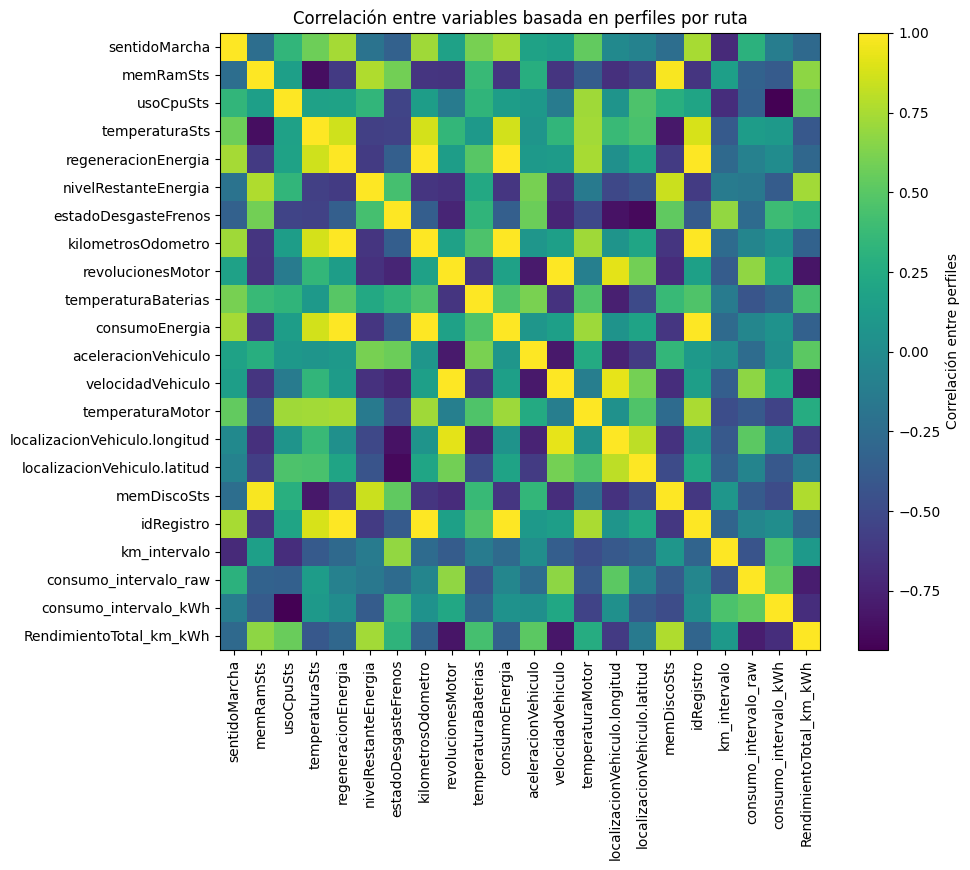

In [24]:
if perfiles_ruta is not None and perfiles_ruta.shape[0] >= 2:
    corr_perfiles = perfiles_ruta.corr()

    display(corr_perfiles.round(3))

    if corr_perfiles.shape[0] <= 30:
        plt.figure(figsize=(
            max(8, corr_perfiles.shape[0] * 0.45),
            max(6, corr_perfiles.shape[0] * 0.40)
        ))
        plt.imshow(corr_perfiles, aspect='auto')
        plt.xticks(
            range(len(corr_perfiles.columns)),
            corr_perfiles.columns,
            rotation=90
        )
        plt.yticks(
            range(len(corr_perfiles.index)),
            corr_perfiles.index
        )
        plt.colorbar(label='Correlación entre perfiles')
        plt.title('Correlación entre variables basada en perfiles por ruta')
        plt.tight_layout()
        plt.show()
    else:
        print('La matriz tiene más de 30 variables; se muestra la tabla sin mapa de calor.')

### 7.6 K-Means transpuesto con Elbow Method y Silhouette

Se muestran ambos criterios específicamente para la matriz transpuesta, siempre que existan suficientes variables.
Silhouette se utiliza para proponer un número de clusters; Elbow permite contrastar visualmente la reducción de inercia.

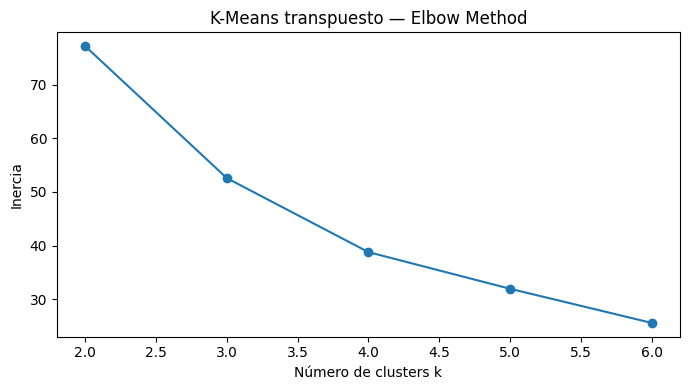

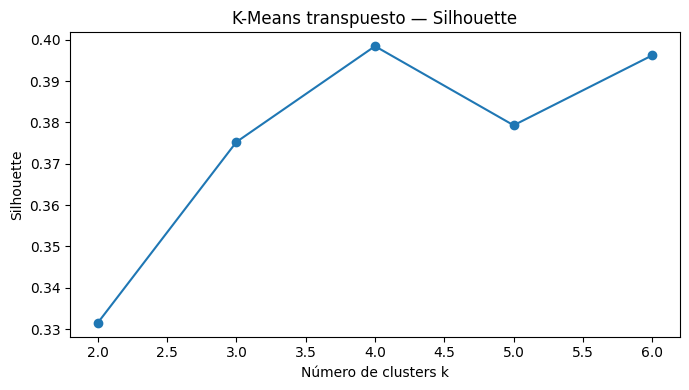

In [25]:
if 'resultados_t' in globals() and isinstance(resultados_t, pd.DataFrame) and not resultados_t.empty:
    plt.figure(figsize=(7, 4))
    plt.plot(resultados_t['k'], resultados_t['Inercia'], marker='o')
    plt.xlabel('Número de clusters k')
    plt.ylabel('Inercia')
    plt.title('K-Means transpuesto — Elbow Method')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(resultados_t['k'], resultados_t['Silhouette'], marker='o')
    plt.xlabel('Número de clusters k')
    plt.ylabel('Silhouette')
    plt.title('K-Means transpuesto — Silhouette')
    plt.tight_layout()
    plt.show()
else:
    print('No se generaron resultados K-Means transpuestos.')

### 7.7 Clustering aglomerativo experimental

El clustering aglomerativo construye una jerarquía de grupos y puede revelar estructuras que K-Means no identifica.
Por su costo computacional se limita a una muestra pequeña en el clustering de observaciones.

Se utiliza el mismo número de clusters propuesto para K-Means, lo que permite comparar ambas particiones.

In [26]:
if len(X_cluster) > MAX_FILAS_AGLOMERATIVO:
    rng = np.random.default_rng(SEMILLA)
    idx_agg = np.sort(
        rng.choice(
            len(X_cluster),
            size=MAX_FILAS_AGLOMERATIVO,
            replace=False
        )
    )
    X_agg = X_cluster[idx_agg]
else:
    idx_agg = np.arange(len(X_cluster))
    X_agg = X_cluster

aglomerativo = AgglomerativeClustering(
    n_clusters=K_OPTIMO,
    linkage='ward'
)
labels_agg = aglomerativo.fit_predict(X_agg)

print('Registros usados:', len(X_agg))
print('Clusters:', K_OPTIMO)
display(
    pd.Series(labels_agg)
    .value_counts()
    .sort_index()
    .rename('Registros')
    .to_frame()
)

if len(np.unique(labels_agg)) > 1:
    if len(X_agg) > 3_000:
        rng = np.random.default_rng(SEMILLA)
        idx_sil_agg = rng.choice(len(X_agg), 3_000, replace=False)
    else:
        idx_sil_agg = np.arange(len(X_agg))

    sil_agg = silhouette_score(
        X_agg[idx_sil_agg],
        labels_agg[idx_sil_agg]
    )
    print('Silhouette aglomerativo:', round(sil_agg, 4))

Registros usados: 377
Clusters: 8


,Registros
0,43
1,250
2,19
3,28
4,9
5,3
6,9
7,16


Silhouette aglomerativo: 0.7026


## 8. Resumen automático de la fase exploratoria

El siguiente bloque consolida algunos indicadores útiles para documentar los resultados antes de avanzar a una segunda
fase de Machine Learning.

La decisión posterior debería basarse en:
- calidad de datos y cantidad de nulos residuales;
- comportamiento de `RendimientoTotal_km_kWh`;
- cantidad de componentes PCA necesarios;
- estabilidad e interpretabilidad de K-Means;
- nivel de ruido de DBSCAN;
- relación entre clusters, rutas, horario y variables energéticas.

In [27]:
print('RESUMEN DE LA FASE EXPLORATORIA ')
print(f'Registros del dataset: {len(df):,}')
print(f'Variables originales: {df.shape[1]}')
print(f'Registros completos usados en ML: {len(X_modelo):,}')
print(f'Variables en matriz de modelado: {X_modelo.shape[1]}')
print(f'Componentes PCA seleccionados (>=90% varianza): {N_COMPONENTES_PCA}')
print(
    'Varianza explicada acumulada PCA:',
    round(pca_modelo.explained_variance_ratio_.sum(), 4)
)
print(f'K óptimo K-Means por Silhouette: {K_OPTIMO}')

if 'n_clusters_dbscan' in globals():
    print(f'Clusters encontrados por DBSCAN: {n_clusters_dbscan}')
    print(f'Ruido DBSCAN: {porcentaje_ruido:.2f}%')

if 'RendimientoTotal_km_kWh' in df_features.columns:
    rend = df_features['RendimientoTotal_km_kWh'].dropna()
    if not rend.empty:
        print(
            'Mediana RendimientoTotal:',
            round(rend.median(), 4),
            'km/kWh'
        )

print('\nSiguiente fase sugerida:')
print(
    'Interpretar los clusters contra ruta, franja horaria, SOC, consumo, '
    'regeneración y rendimiento; posteriormente definir variables objetivo '
    'para modelos supervisados o de detección de anomalías.'
)

========== RESUMEN DE LA FASE EXPLORATORIA ==========
Registros del dataset: 377
Variables originales: 35
Registros completos usados en ML: 377
Variables en matriz de modelado: 23
Componentes PCA seleccionados (>=90% varianza): 2
Varianza explicada acumulada PCA: 0.987
K óptimo K-Means por Silhouette: 8
Clusters encontrados por DBSCAN: 4
Ruido DBSCAN: 7.69%
Mediana RendimientoTotal: 335.0 km/kWh

Siguiente fase sugerida:
Interpretar los clusters contra ruta, franja horaria, SOC, consumo, regeneración y rendimiento; posteriormente definir variables objetivo para modelos supervisados o de detección de anomalías.


## 9. Guardar resultados principales — opcional

Este bloque guarda en Drive una copia del dataset con las variables nuevas y los clusters K-Means asignados a la muestra
utilizada. Se mantiene separado para que el usuario decida cuándo generar archivos de salida.

In [28]:
# EJECUTAR SI SE DESEA GUARDAR LOS RESULTADOS
#
# CARPETA_RESULTADOS = Path(
#     '/content/drive/MyDrive/MANTENIMIENTOESA/Resultados_ML_BUS7838'
# )
# CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
#
# RUTA_FEATURES = CARPETA_RESULTADOS / 'BUS7838_features_exploratorias.csv'
# RUTA_CLUSTERS = CARPETA_RESULTADOS / 'BUS7838_clusters_kmeans.csv'
#
# df_features.to_csv(
#     RUTA_FEATURES,
#     index=False,
#     encoding='utf-8-sig'
# )
#
# df_cluster_resultado.to_csv(
#     RUTA_CLUSTERS,
#     index=False,
#     encoding='utf-8-sig'
# )
#
# print('Guardado:', RUTA_FEATURES)
# print('Guardado:', RUTA_CLUSTERS)